# 07MIAR - Redes Neuronales y Deep Learning
## Proyecto de programación: *Deep Vision in classification tasks*
### Clasificación de tumores cerebrales en resonancias magnéticas: CNN desde cero vs. redes preentrenadas

Autores: Jorge Ramilo Plata, Ricardo Germes Serrano y Sebastián Alfredo Panesso Laverde

---

Hola. En este notebook resolvemos el proyecto de programación de la materia. El problema que escogimos es clasificar imágenes de resonancia magnética (MRI) del cerebro en cuatro clases: tres tipos de tumor (glioma, meningioma y tumor de hipófisis) y sin tumor.

Vamos a atacar el problema con las dos estrategias que pide la actividad:

1. Una CNN diseñada y entrenada desde cero.
2. Redes preentrenadas en ImageNet (VGG16 y MobileNetV2) con *transfer learning* y *fine-tuning*.




# 0. Configuración del entorno

In [2]:
import os
import sys
import time
import zipfile
import hashlib
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

import tensorflow as tf
from tensorflow.keras import layers, regularizers
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout,
                                     BatchNormalization, GlobalAveragePooling2D, Rescaling)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import VGG16, MobileNetV2
from tensorflow.keras.applications import vgg16, mobilenet_v2

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neighbors import NearestNeighbors

# Semilla para reproducibilidad
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Saber si estamos en Colab o en local (así el notebook sirve en los dos lados)
EN_COLAB = 'google.colab' in sys.modules

print("TensorFlow:", tf.__version__)
print("¿Estamos en Colab?:", EN_COLAB)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
¿Estamos en Colab?: True
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Dejamos los parámetros generales en un solo lugar:

- `IMG_SIZE = 160`: las resonancias vienen en tamaños distintos (la mayoría alrededor de 512×512). Las llevamos a 160×160, que es el mismo tamaño que usamos en el ejemplo de MobileNetV2 de clase. Nos pareció un buen punto medio: los tumores siguen siendo visibles y el dataset completo cabe en la RAM de Colab como array de NumPy.
- `BATCH_SIZE = 32`: como el dataset es pequeño (unas 7.000 imágenes), preferimos batches más pequeños para tener más actualizaciones de pesos por época.

In [3]:
IMG_SIZE = 160
BATCH_SIZE = 32

# Nombres de las carpetas del dataset y nombre "bonito" para las gráficas
CARPETAS_CLASES = ['glioma', 'meningioma', 'notumor', 'pituitary']
CLASES = ['glioma', 'meningioma', 'sin tumor', 'hipófisis']
NUM_CLASES = len(CLASES)
IDX_SIN_TUMOR = CLASES.index('sin tumor')

DATASET_DIR = 'brain_mri'

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_FOLDER = "/content/drive/MyDrive/07MIAR_Proyecto_Programacion/"
else:
    BASE_FOLDER = "./"

os.makedirs(BASE_FOLDER, exist_ok=True)
print("Los modelos se guardan en:", BASE_FOLDER)

Mounted at /content/drive
Los modelos se guardan en: /content/drive/MyDrive/07MIAR_Proyecto_Programacion/


# 1. Selección y carga del dataset

## 1.1 ¿Por qué escogimos este dataset?

Usamos el dataset Brain Tumor MRI Dataset de Kaggle (`masoudnickparvar/brain-tumor-mri-dataset`). Nuestras razones:

- Es un problema de clasificación de imágenes con 4 clases bien definidas: glioma, meningioma, tumor de hipófisis (*pituitary*) y sin tumor (*notumor*).
- Tiene alrededor de 7.000 imágenes, suficientes para entrenar y evaluar, pero no tantas como para que una CNN desde cero lo tenga fácil. Eso hace que el sobreajuste y las técnicas de regularización tengan un papel importante.
- Es un problema real con impacto: ayudar a clasificar tumores cerebrales es una aplicación conocida del Deep Learning en medicina.


## 1.2 Descarga con la API de Kaggle

Función reutilizable que descarga y descomprime el dataset.

In [ ]:
%%capture
# Instalamos/actualizamos la API de Kaggle. A diferencia del ejemplo del enunciado no usamos --no-deps,
# porque las versiones nuevas (las que aceptan los tokens KGAT_) necesitan el paquete kagglesdk
!pip install --upgrade kaggle

In [ ]:
# Configuramos el token de Kaggle sin escribirlo en el notebook
if EN_COLAB and not os.environ.get('KAGGLE_API_TOKEN') \
        and not os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json')):
    token = None
    try:
        from google.colab import userdata
        token = userdata.get('KAGGLE_API_TOKEN')   # si se guardó como secreto de Colab
    except Exception:
        token = None
    if not token:
        from getpass import getpass
        token = getpass("Pega tu token de Kaggle (empieza por KGAT_) y presiona Enter: ")
    os.environ['KAGGLE_API_TOKEN'] = token.strip()
    print("Token de Kaggle configurado (no se muestra por seguridad).")

Token de Kaggle configurado (no se muestra por seguridad).


In [ ]:
def descargar_dataset_kaggle(dataset, carpeta_destino):
    '''Descarga un dataset de Kaggle y lo descomprime en carpeta_destino.
    Si ya está descargado no hace nada (así no lo bajamos cada vez que reiniciamos el entorno).'''
    if os.path.exists(carpeta_destino) and len(os.listdir(carpeta_destino)) > 0:
        print("El dataset ya estaba descargado en", carpeta_destino)
        return carpeta_destino

    os.makedirs(carpeta_destino, exist_ok=True)
    archivo_zip = dataset.split('/')[-1] + '.zip'
    if not os.path.exists(archivo_zip):
        os.system(f'kaggle datasets download -d {dataset}')

    with zipfile.ZipFile(archivo_zip, 'r') as z:
        z.extractall(carpeta_destino)
    print("Dataset listo en:", carpeta_destino)
    return carpeta_destino


descargar_dataset_kaggle('masoudnickparvar/brain-tumor-mri-dataset', DATASET_DIR)

Dataset listo en: brain_mri


'brain_mri'

## 1.3 Listado de las imágenes

El dataset viene organizado en carpetas: `Training/<clase>/` y `Testing/<clase>/`, o sea que la etiqueta es el nombre de la carpeta. Recorremos todo con `os.walk` y armamos una tabla con la ruta, la clase y la partición original de cada imagen.

In [ ]:
registros = []
for raiz, _, archivos in os.walk(DATASET_DIR):
    carpeta = os.path.basename(raiz).lower().replace('_', '')   # por si viene como "no_tumor"
    if carpeta in CARPETAS_CLASES:
        particion = os.path.basename(os.path.dirname(raiz))      # Training o Testing
        for f in sorted(archivos):
            if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                registros.append({'ruta': os.path.join(raiz, f),
                                  'particion_original': particion,
                                  'etiqueta': CARPETAS_CLASES.index(carpeta)})

df = pd.DataFrame(registros)
df['clase'] = df['etiqueta'].map(lambda i: CLASES[i])
print("Total de imágenes encontradas:", len(df))
pd.crosstab(df['clase'], df['particion_original'], margins=True, margins_name='Total')

Total de imágenes encontradas: 7200


particion_original,Testing,Training,Total
clase,,,
glioma,400,1400,1800
hipófisis,400,1400,1800
meningioma,400,1400,1800
sin tumor,400,1400,1800
Total,1600,5600,7200


## 1.4 Lectura de las imágenes

Leemos cada imagen con `cv2` (como en el ejemplo del enunciado), la pasamos de BGR a RGB y la redimensionamos a 160×160. Mientras cargamos, aprovechamos para guardar información que necesitamos para la inspección:

- Tamaño original de cada imagen.
- Si es realmente gris (las resonancias son en escala de grises, pero queremos comprobar si los 3 canales son iguales).
- Dos "huellas" (hash) de cada imagen para detectar duplicados:
  - `hash_exacto`: el MD5 de los bytes del archivo. Si dos archivos tienen el mismo, son exactamente el mismo archivo.
  - Una versión mini de cada imagen (16×16 en gris). Después buscamos imágenes cuyas versiones mini sean casi iguales (sección 2.5). Así detectamos la misma resonancia aunque esté guardada con otro tamaño o compresión, que con un hash exacto no se detectaría porque basta un píxel distinto para que cambie.

In [ ]:
def cargar_imagenes(rutas, img_size):
    '''Lee las imágenes, las pasa a RGB y las redimensiona. También calcula datos para la inspección.'''
    X = np.zeros((len(rutas), img_size, img_size, 3), dtype=np.uint8)
    minis = np.zeros((len(rutas), 16 * 16), dtype=np.float32)
    info = []
    for i, ruta in enumerate(rutas):
        with open(ruta, 'rb') as f:
            contenido = f.read()
        img = cv2.imdecode(np.frombuffer(contenido, np.uint8), cv2.IMREAD_COLOR)
        if img is None:          # por si alguna imagen viene dañada
            minis[i] = 100 + i   # vector "lejano" para que no se agrupe con ninguna otra
            info.append({'valida': False})
            continue
        gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        minis[i] = cv2.resize(gris, (16, 16), interpolation=cv2.INTER_AREA).ravel() / 255.0
        info.append({
            'valida': True,
            'alto': img.shape[0],
            'ancho': img.shape[1],
            'es_gris': bool(np.abs(img[..., 0].astype(int) - img[..., 2].astype(int)).mean() < 2),
            'hash_exacto': hashlib.md5(contenido).hexdigest(),
        })
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        X[i] = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA)
    return X, minis, pd.DataFrame(info)


inicio = time.time()
X_todo, minis, info = cargar_imagenes(df['ruta'].tolist(), IMG_SIZE)
df = pd.concat([df.reset_index(drop=True), info], axis=1)
print(f"Tiempo de carga: {time.time() - inicio:.1f} s")
print("Imágenes que no se pudieron leer:", int((~df['valida']).sum()))
print("Forma de X_todo:", X_todo.shape, "| tipo:", X_todo.dtype)
print(f"Memoria que ocupa: {X_todo.nbytes / 1e6:.0f} MB")

Tiempo de carga: 40.1 s
Imágenes que no se pudieron leer: 0
Forma de X_todo: (7200, 160, 160, 3) | tipo: uint8
Memoria que ocupa: 553 MB


# 2. Inspección y análisis del dataset

Antes de entrenar queremos entender bien los datos: cómo se ven, cómo están repartidas las clases, qué tamaños tienen y si hay problemas de calidad.

## 2.1 Ejemplos de cada clase

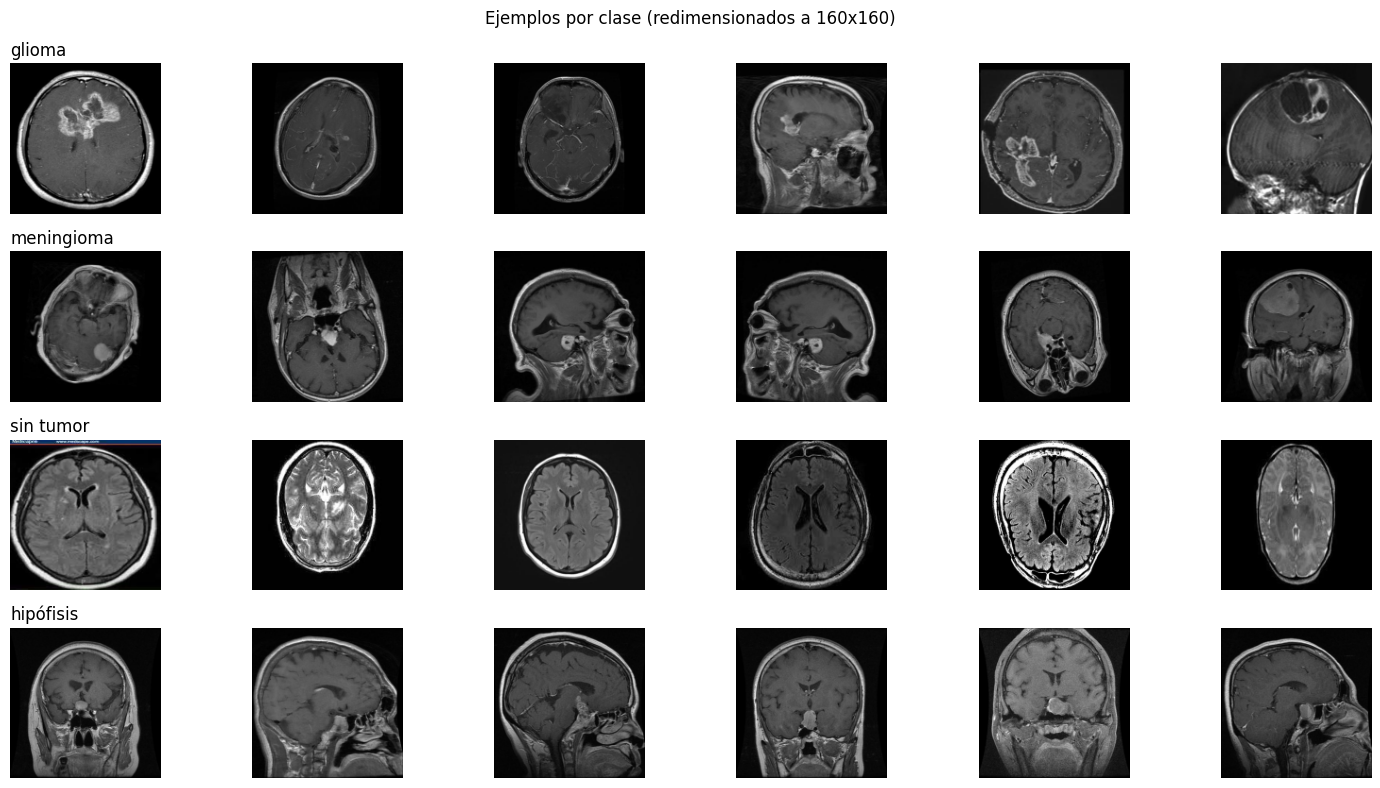

In [ ]:
plt.figure(figsize=(15, 8))
for c in range(NUM_CLASES):
    idx = df.index[df['etiqueta'] == c][:6]
    for j, i in enumerate(idx):
        plt.subplot(NUM_CLASES, 6, c * 6 + j + 1)
        plt.imshow(X_todo[i])
        plt.axis('off')
        if j == 0:
            plt.title(CLASES[c], loc='left', fontsize=12)
plt.suptitle(f"Ejemplos por clase (redimensionados a {IMG_SIZE}x{IMG_SIZE})")
plt.tight_layout()
plt.show()

Algunas cosas que se ven en los ejemplos:

- Hay resonancias tomadas desde distintos planos: axial (vista desde arriba), sagital (de lado) y coronal (de frente).
- El contraste y el brillo cambian bastante entre imágenes.
- Muchas imágenes tienen bordes negros grandes alrededor del cráneo.
- Los tumores de hipófisis suelen estar en la base del cerebro, los meningiomas cerca del borde del cráneo y los gliomas dentro del tejido cerebral. Son pistas de posición y forma.

## 2.2 ¿Son realmente imágenes en gris?

In [ ]:
print(f"Imágenes con los 3 canales prácticamente iguales (gris): {df['es_gris'].mean() * 100:.1f} %")
print(df.groupby('clase')['es_gris'].mean().round(3))

Imágenes con los 3 canales prácticamente iguales (gris): 99.4 %
clase
glioma        1.000
hipófisis     1.000
meningioma    1.000
sin tumor     0.976
Name: es_gris, dtype: float64


Prácticamente todas son en escala de grises guardadas en formato de 3 canales. Decidimos mantener los 3 canales por dos razones:

1. Las redes preentrenadas en ImageNet esperan entradas RGB de 3 canales; si les pasamos una imagen gris con los 3 canales iguales, funcionan sin cambiar nada.
2. Así la CNN desde cero y las preentrenadas reciben exactamente la misma entrada y la comparación es justa.

## 2.3 Distribución de las clases

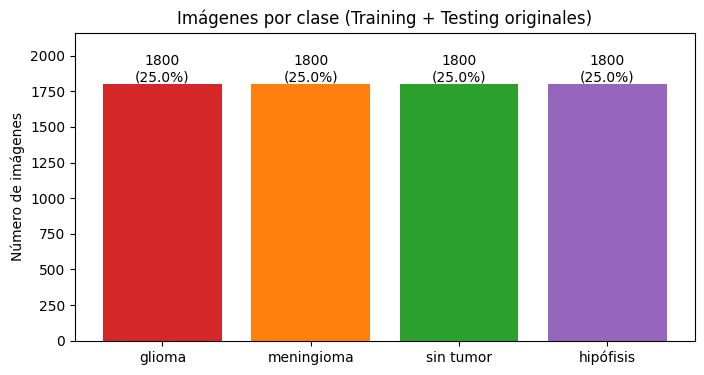

In [ ]:
conteo = df['clase'].value_counts().reindex(CLASES)
plt.figure(figsize=(8, 4))
plt.bar(CLASES, conteo.values, color=['tab:red', 'tab:orange', 'tab:green', 'tab:purple'])
for i, v in enumerate(conteo.values):
    plt.text(i, v, f"{v}\n({v / len(df) * 100:.1f}%)", ha='center', va='bottom')
plt.title("Imágenes por clase (Training + Testing originales)")
plt.ylabel("Número de imágenes")
plt.ylim(0, conteo.max() * 1.2)
plt.show()

Viendo el dataset tal como viene, las clases parecen perfectamente equilibradas. Pero ojo: este conteo todavía incluye las imágenes repetidas. En la sección 2.5 volvemos a revisar la distribución después de limpiar los duplicados, porque puede cambiar bastante.

## 2.4 Dimensiones de las imágenes originales

Altura -> min: 167, max: 1446, mediana: 512
Ancho  -> min: 150, max: 1375, mediana: 512
Imágenes cuadradas: 78.7 %

Tamaños más frecuentes:
512x512    5014
225x225     338
630x630      90
251x201      57
221x228      51
Name: count, dtype: int64


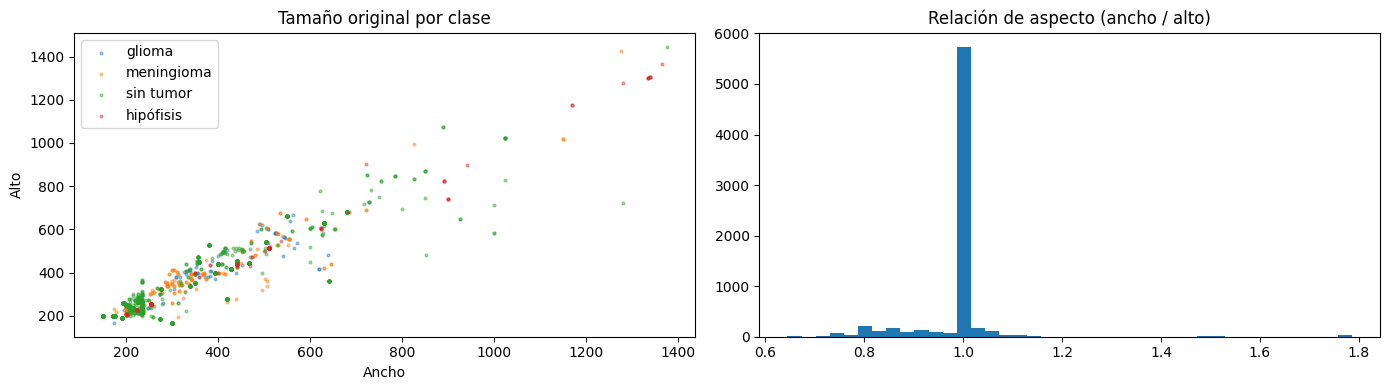

In [ ]:
validas = df[df['valida']]
print(f"Altura -> min: {validas['alto'].min()}, max: {validas['alto'].max()}, mediana: {validas['alto'].median():.0f}")
print(f"Ancho  -> min: {validas['ancho'].min()}, max: {validas['ancho'].max()}, mediana: {validas['ancho'].median():.0f}")
print(f"Imágenes cuadradas: {(validas['alto'] == validas['ancho']).mean() * 100:.1f} %")
print("\nTamaños más frecuentes:")
print((validas['alto'].astype(str) + 'x' + validas['ancho'].astype(str)).value_counts().head(5))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for c in range(NUM_CLASES):
    sub = validas[validas['etiqueta'] == c]
    axes[0].scatter(sub['ancho'], sub['alto'], s=4, alpha=0.4, label=CLASES[c])
axes[0].set_xlabel("Ancho")
axes[0].set_ylabel("Alto")
axes[0].set_title("Tamaño original por clase")
axes[0].legend()
axes[1].hist(validas['ancho'] / validas['alto'], bins=40)
axes[1].set_title("Relación de aspecto (ancho / alto)")
plt.tight_layout()
plt.show()

Las imágenes no tienen un tamaño fijo, aunque la mayoría son cuadradas y de 512×512. Por eso redimensionamos todas a 160×160.

Algo que conviene revisar en el gráfico por colores: si una clase tuviera tamaños muy distintos al resto (por ejemplo, si todas las "sin tumor" vinieran de otro hospital con otra resolución), la red podría aprender a distinguir la clase por el tamaño o el estilo de la imagen y no por el tumor. Al redimensionar todo a 160×160 eliminamos la pista del tamaño, pero el estilo (contraste, bordes) sigue ahí; lo revisamos más adelante con Grad-CAM.

## 2.5 Detección de imágenes duplicadas

Este dataset junta imágenes de tres fuentes públicas distintas, así que puede haber la misma resonancia repetida, a veces en `Training` y en `Testing` al mismo tiempo.

¿Por qué importa? Si una imagen del test también está en el entrenamiento, el modelo ya la "vio" y la evaluación sale inflada.

In [ ]:
# 1) Agrupamos las imágenes que son "visualmente la misma": para cada versión mini buscamos las que estén
#    a una distancia muy pequeña (el umbral lo justificamos en la gráfica de abajo).
UMBRAL_DUPLICADO = 0.1
vecinos = NearestNeighbors(radius=UMBRAL_DUPLICADO).fit(minis).radius_neighbors(minis, return_distance=False)
grupo = -np.ones(len(df), dtype=int)
for i in range(len(df)):
    if grupo[i] == -1:
        grupo[vecinos[i]] = np.where(grupo[vecinos[i]] == -1, i, grupo[vecinos[i]])
df['hash_visual'] = grupo     # id del grupo de imágenes iguales

# 2) Contamos los distintos tipos de duplicados
validas = df[df['valida']].copy()
n_dup_exactos = validas.duplicated('hash_exacto', keep='first').sum()
n_dup_visuales = validas.duplicated('hash_visual', keep='first').sum()

# Duplicados que cruzan Training y Testing (fuga de datos en la partición original)
particiones_por_hash = validas.groupby('hash_visual')['particion_original'].nunique()
hashes_cruzados = particiones_por_hash[particiones_por_hash > 1].index
n_test_contaminado = ((validas['particion_original'] == 'Testing') &
                      validas['hash_visual'].isin(hashes_cruzados)).sum()

# Duplicados con etiquetas distintas (la misma imagen en dos clases)
etiquetas_por_hash = validas.groupby('hash_visual')['etiqueta'].nunique()
hashes_conflicto = etiquetas_por_hash[etiquetas_por_hash > 1].index

print(f"Copias exactas (mismo archivo)            : {n_dup_exactos}")
print(f"Copias visuales (incluye las exactas)     : {n_dup_visuales}")
print(f"Imágenes de Testing que también están en Training: {n_test_contaminado}")
print(f"Grupos de duplicados con etiquetas distintas: {len(hashes_conflicto)}")

Copias exactas (mismo archivo)            : 187
Copias visuales (incluye las exactas)     : 1062
Imágenes de Testing que también están en Training: 412
Grupos de duplicados con etiquetas distintas: 2


### ¿Cómo escogimos el umbral de 0.1?

No quisimos poner un número "a ojo", así que miramos la distancia de cada imagen a la imagen más parecida del resto del dataset. Si hay duplicados, debería aparecer un grupo de imágenes con distancia casi cero, separado del resto.

La primera vez que lo probamos usamos un umbral de 0.5 y se eliminaba más de un tercio del dataset. Al revisar los pares, la mayoría no eran copias sino cortes vecinos de la misma resonancia (imágenes distintas pero muy parecidas, porque una resonancia se compone de muchos "cortes" seguidos del cerebro).

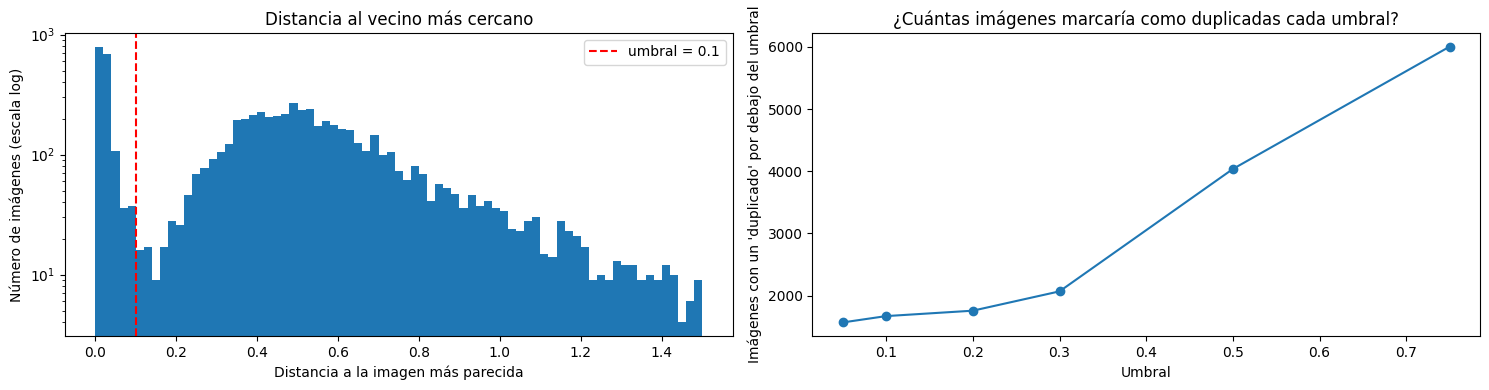

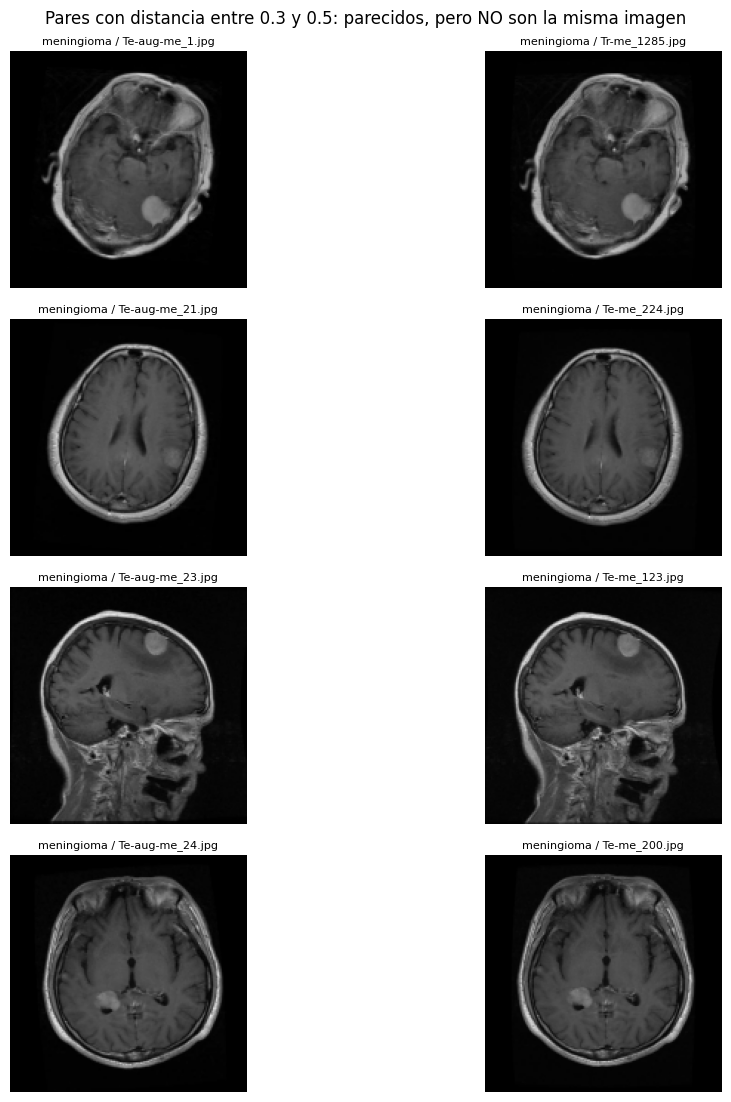

In [ ]:
distancia_vecino = NearestNeighbors(n_neighbors=2).fit(minis).kneighbors(minis)[0][:, 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].hist(distancia_vecino, bins=np.linspace(0, 1.5, 76), color='tab:blue')
axes[0].axvline(UMBRAL_DUPLICADO, color='red', linestyle='--', label=f'umbral = {UMBRAL_DUPLICADO}')
axes[0].set_yscale('log')
axes[0].set_xlabel("Distancia a la imagen más parecida")
axes[0].set_ylabel("Número de imágenes (escala log)")
axes[0].set_title("Distancia al vecino más cercano")
axes[0].legend()

umbrales = [0.05, 0.1, 0.2, 0.3, 0.5, 0.75]
axes[1].plot(umbrales, [np.sum(distancia_vecino < u) for u in umbrales], 'o-')
axes[1].set_xlabel("Umbral")
axes[1].set_ylabel("Imágenes con un 'duplicado' por debajo del umbral")
axes[1].set_title("¿Cuántas imágenes marcaría como duplicadas cada umbral?")
plt.tight_layout()
plt.show()

# Pares justo por ENCIMA del umbral, para ver que ya no son copias
cerca = np.where((distancia_vecino > 0.3) & (distancia_vecino < 0.5))[0][:4]
vecino = NearestNeighbors(n_neighbors=2).fit(minis).kneighbors(minis[cerca])[1][:, 1]
if len(cerca) > 0:
    plt.figure(figsize=(12, 2.8 * len(cerca)))
    for n, (a, b) in enumerate(zip(cerca, vecino)):
        for j, i in enumerate([a, b]):
            plt.subplot(len(cerca), 2, n * 2 + j + 1)
            plt.imshow(X_todo[i])
            plt.title(f"{df.loc[i, 'clase']} / {os.path.basename(df.loc[i, 'ruta'])}", fontsize=8)
            plt.axis('off')
    plt.suptitle("Pares con distancia entre 0.3 y 0.5: parecidos, pero NO son la misma imagen")
    plt.tight_layout()
    plt.show()

El histograma muestra dos grupos bien separados: uno pegado al cero (copias reales: la misma imagen guardada otra vez, a veces con otra compresión o un leve filtro) y otro mucho más grande alrededor de 0.3-0.8 (imágenes distintas, incluidos los cortes vecinos de una misma resonancia). Entre los dos hay un valle alrededor de 0.1-0.2. La curva de la derecha dice lo mismo: casi no crece entre 0.05 y 0.2, pero a partir de 0.3 se dispara. Por eso escogimos 0.1, justo en el valle: se queda con las copias claras y no toca las imágenes distintas.

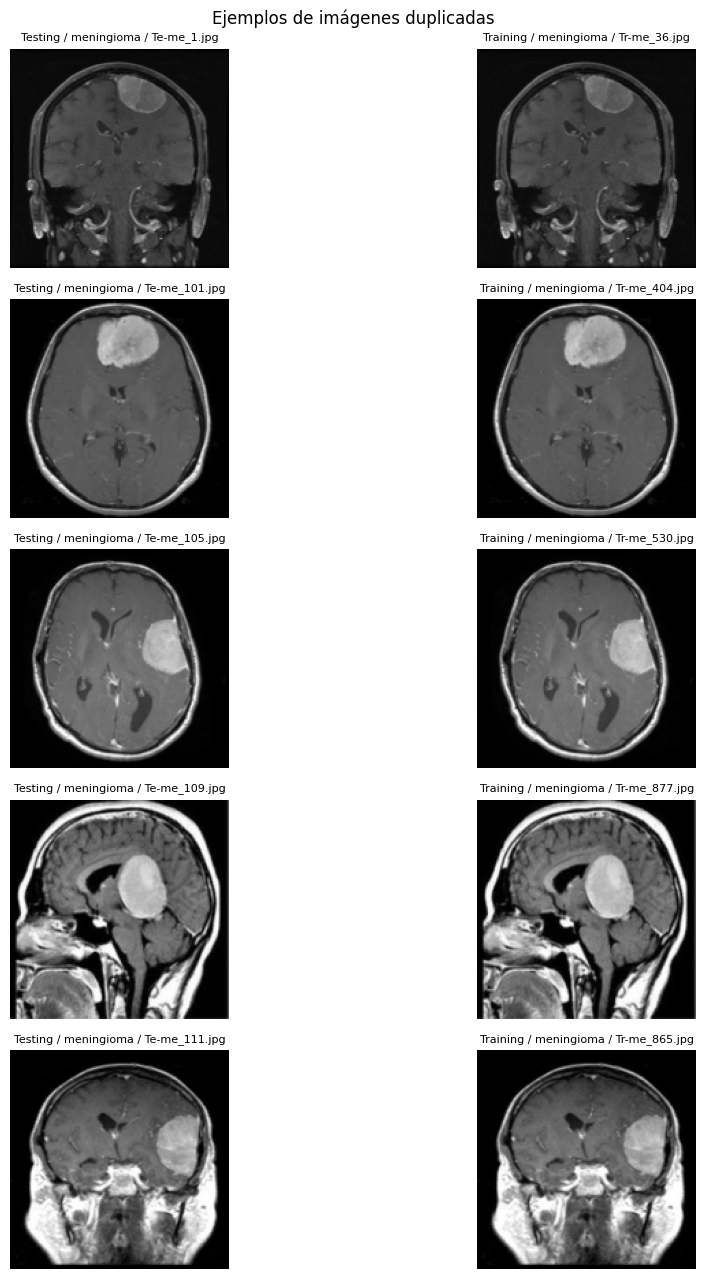

In [ ]:
# Mostramos algunos pares de duplicados para comprobar visualmente que de verdad son la misma imagen
grupos = validas[validas.duplicated('hash_visual', keep=False)].groupby('hash_visual')
pares = [g.index[:2].tolist() for _, g in grupos][:5]
if pares:
    plt.figure(figsize=(12, 2.6 * len(pares)))
    for n, (a, b) in enumerate(pares):
        for j, i in enumerate([a, b]):
            plt.subplot(len(pares), 2, n * 2 + j + 1)
            plt.imshow(X_todo[i])
            plt.title(f"{df.loc[i, 'particion_original']} / {df.loc[i, 'clase']} / {os.path.basename(df.loc[i, 'ruta'])}", fontsize=8)
            plt.axis('off')
    plt.suptitle("Ejemplos de imágenes duplicadas")
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron duplicados.")

### Decisión sobre los duplicados

Con lo que muestra la celda anterior tomamos tres decisiones:

1. Nos quedamos con una sola copia de cada imagen repetida.
2. Si una misma imagen aparece con dos etiquetas distintas, la eliminamos del todo, porque no sabemos cuál es la correcta y le enseñaríamos cosas contradictorias a la red.
3. No usamos la partición original Training/Testing. Como hay imágenes de Testing que también están en Training, juntamos todo (ya sin duplicados) y hacemos nuestra propia división en train, validación y test. Así nos aseguramos de que el test sea realmente de imágenes nunca vistas.

Limitación que no podemos resolver: como vimos con el umbral, el dataset tiene varios cortes de la misma resonancia (del mismo paciente). Lo ideal sería dividir por paciente, para que ningún paciente aparezca a la vez en train y en test, pero el dataset no trae esa información.

Imágenes originales: 7200  ->  imágenes únicas que usamos: 6136  (eliminadas: 1064)


,antes,después,eliminadas_%,proporción_final_%
glioma,1800,1776,1.3,28.9
meningioma,1800,1674,7.0,27.3
sin tumor,1800,930,48.3,15.2
hipófisis,1800,1756,2.4,28.6


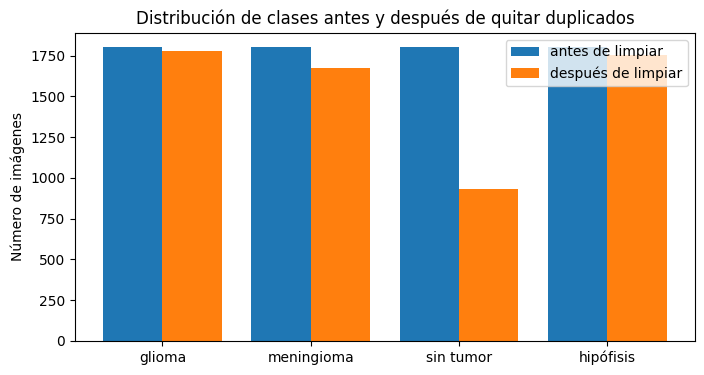

In [ ]:
mascara = (df['valida']
           & ~df['hash_visual'].isin(hashes_conflicto)
           & ~df.duplicated('hash_visual', keep='first'))

X = X_todo[mascara.values]
y = df.loc[mascara, 'etiqueta'].values.astype(np.int32)
del X_todo, minis
gc.collect()

print(f"Imágenes originales: {len(df)}  ->  imágenes únicas que usamos: {len(X)}  (eliminadas: {len(df) - len(X)})")

antes = df['clase'].value_counts().reindex(CLASES)
despues = pd.Series(y).map(lambda i: CLASES[i]).value_counts().reindex(CLASES)
tabla = pd.DataFrame({'antes': antes, 'después': despues,
                      'eliminadas_%': ((1 - despues / antes) * 100).round(1),
                      'proporción_final_%': (despues / despues.sum() * 100).round(1)})
display(tabla)

x = np.arange(NUM_CLASES)
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, antes.values, 0.4, label='antes de limpiar')
plt.bar(x + 0.2, despues.values, 0.4, label='después de limpiar')
plt.xticks(x, CLASES)
plt.ylabel("Número de imágenes")
plt.title("Distribución de clases antes y después de quitar duplicados")
plt.legend()
plt.show()

Este resultado nos sorprendió: los duplicados no estaban repartidos por igual. La clase "sin tumor" es la que más copias tenía (se eliminó el 48 % de sus imágenes). Pasa de tener 1.800 imágenes, como las demás, a solo 930, más o menos la mitad que cada clase con tumor. Si no hubiéramos revisado los duplicados, habríamos creído que el dataset estaba balanceado y que tenía muchos más ejemplos sanos de los que realmente hay.

Consecuencias para el resto del proyecto:

- Ahora hay un desbalance moderado. La accuracy sigue siendo útil, pero vamos a mirar también el F1 macro y el recall de cada clase, para que una clase pequeña no quede escondida detrás de un buen promedio.
- El clasificador trivial (siempre la clase más frecuente) saca alrededor de un 29 %, y uno al azar un 25 %. Ese es el piso que los modelos tienen que superar.
- Con menos ejemplos de "sin tumor", la red tiene menos información para aprender qué es un cerebro sano. Habrá que revisar en la matriz de confusión cómo afecta esto a los errores.

## 2.6 Intensidad de los píxeles

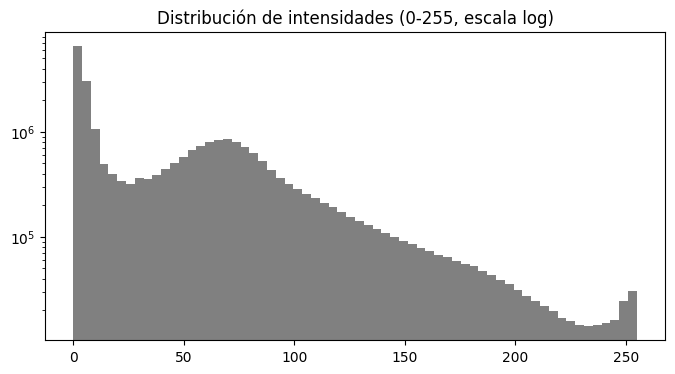

Porcentaje de píxeles casi negros (< 10): 39.9 %


In [ ]:
muestra = X[np.random.default_rng(SEED).choice(len(X), min(1000, len(X)), replace=False)]
plt.figure(figsize=(8, 4))
plt.hist(muestra[..., 0].ravel(), bins=64, color='gray')
plt.yscale('log')
plt.title("Distribución de intensidades (0-255, escala log)")
plt.show()
print(f"Porcentaje de píxeles casi negros (< 10): {np.mean(muestra[..., 0] < 10) * 100:.1f} %")

Hay un pico enorme cerca de 0: una buena parte de cada imagen es fondo negro. El resto de valores va hasta 255, así que, igual que en clase con MNIST y CIFAR-10, hay que normalizar antes de meter las imágenes a la red.

# 3. Acondicionamiento y preprocesamiento

## 3.1 División en entrenamiento, validación y test

Dividimos las imágenes únicas en tres subconjuntos estratificados (manteniendo la proporción de cada clase):

- Train (70 %): para ajustar los pesos.
- Validación (15 %): para monitorizar el entrenamiento y tomar todas las decisiones (arquitectura, regularización, learning rate...).
- Test (15 %): solo lo usamos al final con los modelos ya escogidos, para que la evaluación sea honesta.

In [ ]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=SEED)

del X_temp, y_temp, X
gc.collect()

resumen = pd.DataFrame({
    'Train': np.bincount(y_train, minlength=NUM_CLASES),
    'Validación': np.bincount(y_val, minlength=NUM_CLASES),
    'Test': np.bincount(y_test, minlength=NUM_CLASES),
}, index=CLASES)
resumen.loc['Total'] = resumen.sum()
resumen

,Train,Validación,Test
glioma,1243,266,267
meningioma,1172,251,251
sin tumor,650,140,140
hipófisis,1229,264,263
Total,4294,921,921


## 3.2 Normalización y codificación de etiquetas

- Etiquetas: son enteros de 0 a 3, así que usamos una salida `Dense(4, activation='softmax')` con la pérdida `sparse_categorical_crossentropy`, como en los ejemplos de clase con MNIST y CIFAR-10 (no hace falta pasar a one-hot).
- Normalización para la CNN desde cero: en vez de dividir todo el array entre 255 (que crearía una copia en `float32` cuatro veces más grande), ponemos una capa `Rescaling(1./255)` al inicio del modelo. Hace lo mismo que `x / 255.0` pero dentro de la red, y así guardamos las imágenes en `uint8`.
- Normalización para las redes preentrenadas: como vimos en clase, hay que normalizar igual que se hizo al entrenarlas en ImageNet, con el `preprocess_input` de cada arquitectura (sección 6).

## 3.3 Data augmentation

Para algunos experimentos usamos *data augmentation* con las capas de preprocesamiento de Keras (sesión 2 del curso). En imágenes médicas hay que tener más cuidado que con fotos normales, porque una transformación exagerada puede crear algo que no existe en la realidad. Escogimos:

- `RandomFlip("horizontal")`: el cerebro es aproximadamente simétrico izquierda-derecha y un tumor puede estar en cualquiera de los dos lados, así que voltear horizontalmente no cambia la clase.
- No usamos flip vertical: un cerebro de cabeza no aparece nunca en una resonancia real, y en el caso de la hipófisis la posición (base del cerebro) es una pista importante.
- `RandomRotation(0.05)`: rotaciones pequeñas (±18°), porque el paciente no siempre está perfectamente alineado.
- `RandomZoom(0.1)` y `RandomTranslation(0.05, 0.05)`: pequeños cambios de escala y posición, como pasa entre distintos equipos.
- `RandomContrast(0.1)`: el contraste varía entre hospitales (lo vimos en la inspección), así que pequeños cambios de contraste ayudan a que la red no dependa de un equipo concreto.

Estas capas solo actúan durante el entrenamiento; en validación y test la imagen pasa sin cambios.

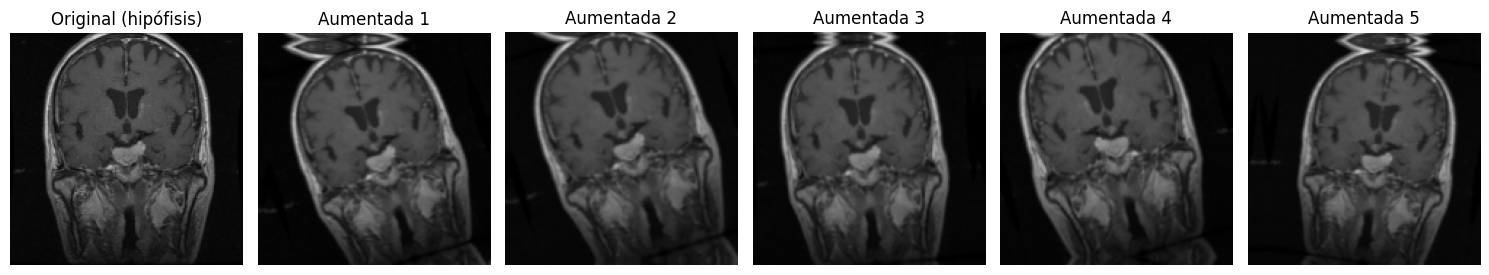

In [ ]:
def crear_data_augmentation(rango_valores=(0, 255)):
    '''Bloque de data augmentation (creamos uno nuevo para cada modelo).
    rango_valores: rango en el que vienen los píxeles. Importa por RandomContrast, que en Keras 3
    recorta (clip) la salida a ese rango. Por defecto es (0, 255), lo que sirve para la CNN desde cero
    porque ahí el augmentation va antes del Rescaling.'''
    return Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomContrast(0.1, value_range=rango_valores),
    ], name="data_augmentation")


# Revisamos visualmente que las transformaciones sigan pareciendo resonancias reales
aug_demo = crear_data_augmentation()
plt.figure(figsize=(15, 3))
plt.subplot(1, 6, 1)
plt.imshow(X_train[0])
plt.title(f"Original ({CLASES[y_train[0]]})")
plt.axis('off')
for i in range(5):
    aumentada = aug_demo(tf.expand_dims(tf.cast(X_train[0], tf.float32), 0), training=True)[0]
    plt.subplot(1, 6, i + 2)
    plt.imshow(np.clip(aumentada.numpy(), 0, 255).astype('uint8'))
    plt.title(f"Aumentada {i + 1}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Las imágenes aumentadas siguen pareciendo resonancias reales y la anatomía se mantiene, así que las transformaciones son razonables.

# 4. Funciones auxiliares

Como vamos a hacer bastantes experimentos, armamos unas funciones para no repetir código:

- `entrenar(...)`: compila, entrena, mide el tiempo y guarda un resumen en `resultados` para la comparación final.
- `graficar_historial(...)`: gráficas de *loss* y *accuracy* de train vs validación (la misma idea que la gráfica de clase).
- `diagnosticar(...)`: imprime la mejor época, el *gap* entre train y validación y un veredicto sencillo de sobreajuste/subajuste. Así tomamos las decisiones con números y no solo "a ojo".
- `evaluar_en_test(...)`: solo se usa al final.

In [ ]:
resultados = []     # resumen de cada experimento
historiales = {}    # historiales completos


def contar_parametros(model):
    entrenables = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
    return int(model.count_params()), entrenables


def entrenar(model, nombre, estrategia, X_tr, y_tr, X_v, y_v, epochs,
             learning_rate=1e-3, callbacks=None, batch_size=BATCH_SIZE):
    '''Compila y entrena el modelo. Guarda el historial y un resumen en `resultados`.'''
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    total, entrenables = contar_parametros(model)
    print(f"[INFO] {nombre}: {total:,} parámetros ({entrenables:,} entrenables)")

    inicio = time.time()
    H = model.fit(X_tr, y_tr,
                  validation_data=(X_v, y_v),
                  epochs=epochs,
                  batch_size=batch_size,
                  callbacks=callbacks,
                  verbose=2)
    duracion = time.time() - inicio

    h = H.history
    mejor = int(np.argmax(h['val_accuracy']))
    resultados.append({
        'experimento': nombre,
        'estrategia': estrategia,
        'epocas': len(h['loss']),
        'mejor_epoca': mejor + 1,
        'train_acc': h['accuracy'][mejor],
        'val_acc': h['val_accuracy'][mejor],
        'val_loss_min': float(np.min(h['val_loss'])),
        'gap_acc': h['accuracy'][mejor] - h['val_accuracy'][mejor],
        'params_total': total,
        'params_entrenables': entrenables,
        'tiempo_s': duracion,
    })
    historiales[nombre] = h
    print(f"[INFO] Tiempo de entrenamiento: {duracion / 60:.1f} min")
    return H


def graficar_historial(H, titulo):
    h = H.history if hasattr(H, 'history') else H
    epocas = np.arange(1, len(h['loss']) + 1)
    plt.style.use("ggplot")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(epocas, h['loss'], label='train_loss')
    axes[0].plot(epocas, h['val_loss'], label='val_loss')
    axes[0].set_title(f"{titulo} - Loss")
    axes[0].set_xlabel("Época")
    axes[0].legend()
    axes[1].plot(epocas, h['accuracy'], label='train_acc')
    axes[1].plot(epocas, h['val_accuracy'], label='val_acc')
    axes[1].set_title(f"{titulo} - Accuracy")
    axes[1].set_xlabel("Época")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


def diagnosticar(nombre):
    '''Resumen numérico del experimento para justificar la siguiente decisión.'''
    h = historiales[nombre]
    mejor = int(np.argmax(h['val_accuracy']))
    epoca_min_loss = int(np.argmin(h['val_loss']))
    ultima = len(h['val_loss']) - 1
    gap = h['accuracy'][mejor] - h['val_accuracy'][mejor]
    gap_final = h['accuracy'][ultima] - h['val_accuracy'][ultima]
    subida_val_loss = h['val_loss'][ultima] - h['val_loss'][epoca_min_loss]

    print(f"===== Diagnóstico: {nombre} =====")
    print(f"Mejor val_accuracy: {h['val_accuracy'][mejor]:.4f} (época {mejor + 1})")
    print(f"train_accuracy en esa época: {h['accuracy'][mejor]:.4f}  -> gap: {gap:.4f}")
    print(f"Última época -> train_acc: {h['accuracy'][ultima]:.4f} | val_acc: {h['val_accuracy'][ultima]:.4f} | gap: {gap_final:.4f}")
    print(f"val_loss mínima: {h['val_loss'][epoca_min_loss]:.4f} (época {epoca_min_loss + 1}); "
          f"al final: {h['val_loss'][ultima]:.4f} (cambio {subida_val_loss:+.4f})")

    if h['accuracy'][ultima] < 0.75 and h['val_accuracy'][mejor] < 0.75:
        veredicto = "SUBAJUSTE: el modelo no logra aprender bien ni siquiera el train."
    elif gap_final > 0.05 or subida_val_loss > 0.15:
        veredicto = ("SOBREAJUSTE: el train sigue mejorando pero la validación se estanca o empeora "
                     "(la val_loss sube desde su mínimo y/o el gap es grande).")
    else:
        veredicto = "BUEN BALANCE: train y validación avanzan juntos, sin sobreajuste marcado."
    print("Veredicto:", veredicto)


def val_acc_de(nombre):
    return max(historiales[nombre]['val_accuracy'])

Piso de referencia (clasificador trivial). Antes de entrenar calculamos qué accuracy sacaría un modelo que siempre predice la clase más frecuente del train.

In [ ]:
clase_mayoritaria = np.bincount(y_train).argmax()
acc_trivial_val = np.mean(y_val == clase_mayoritaria)
acc_trivial_test = np.mean(y_test == clase_mayoritaria)
print(f"Clasificador trivial (siempre '{CLASES[clase_mayoritaria]}'): val_acc = {acc_trivial_val:.4f} | test_acc = {acc_trivial_test:.4f}")
print(f"Clasificador aleatorio (4 clases): ~{1 / NUM_CLASES:.2f}")

Clasificador trivial (siempre 'glioma'): val_acc = 0.2888 | test_acc = 0.2899
Clasificador aleatorio (4 clases): ~0.25


# 5. Estrategia 1: CNN desde cero (*from scratch*)

Vamos construyendo la red paso a paso, cambiando una cosa a la vez para saber qué efecto tiene cada decisión:

| Exp. | Qué cambiamos | Qué queremos comprobar |
|---|---|---|
| E1 | CNN base sencilla (2 bloques, como en clase) | Punto de partida, ver si aprende algo |
| E2 | Red más profunda (4 bloques) + `padding="same"` | Si más capacidad de extracción mejora la validación y cuántos parámetros ahorramos antes del `Flatten` |
| E3 | E2 + *Batch Normalization* + *Dropout* | Si reduce el sobreajuste y estabiliza el entrenamiento |
| E4 | E3 + regularización L2 en los pesos | Si penalizar pesos grandes ayuda a generalizar más |
| E5 | Mejor de E3/E4 + *data augmentation* + *EarlyStopping* | Si "más variedad" de datos corrige el sobreajuste que quede |
| E6 | E5 con *learning rate* más bajo | Efecto de la tasa de aprendizaje sobre la convergencia |

En E1-E4 entrenamos 25 épocas sin EarlyStopping, a propósito, para ver completas las curvas y detectar el sobreajuste. Optimizador Adam con `lr = 0.001` (el de clase) y batch de 32.

In [ ]:
EPOCHS_EXP = 25

## E1: CNN base

Arrancamos con una arquitectura parecida a la de CIFAR-10 de la sesión 2: dos bloques `Conv2D → Conv2D → MaxPooling` con 32 y 64 filtros de 3×3, ReLU, `Flatten`, una densa de 128 y la salida softmax de 4 clases.

Hipótesis: la red va a aprender (muy por encima del ~30 % del clasificador trivial), pero como no tiene regularización y la densa después del `Flatten` va a tener muchísimos parámetros, esperamos sobreajuste rápido, más con solo unas 4.300 imágenes de entrenamiento.

In [ ]:
def crear_cnn_e1():
    entradas = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = Rescaling(1. / 255)(entradas)        # normalización 0-1

    # Bloque 1: CONV => RELU => CONV => RELU => POOL
    x = Conv2D(32, (3, 3), activation='relu')(x)
    x = Conv2D(32, (3, 3), activation='relu')(x)
    x = MaxPooling2D((2, 2))(x)

    # Bloque 2: CONV => RELU => CONV => RELU => POOL
    x = Conv2D(64, (3, 3), activation='relu')(x)
    x = Conv2D(64, (3, 3), activation='relu')(x)
    x = MaxPooling2D((2, 2))(x)

    # Top model
    x = Flatten()(x)
    x = Dense(128, activation='relu')(x)
    salida = Dense(NUM_CLASES, activation='softmax')(x)
    return Model(entradas, salida, name='E1_cnn_base')


model_e1 = crear_cnn_e1()
model_e1.summary()

Model: "E1_cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 156, 156, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 78, 78, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 76, 76, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 74, 74, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 87616)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,214,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,281,060 (43.03 MB)

 Trainable params: 11,281,060 (43.03 MB)

 Non-trainable params: 0 (0.00 B)

En el `summary` se ve lo que vimos en clase sobre el pooling: con solo 2 poolings, al `Flatten` le llega un tensor de 37×37×64 = 87.616 valores, y la `Dense(128)` sola tiene más de 11 millones de parámetros, casi toda la red. Es muchísima capacidad para memorizar con tan pocas imágenes.

[INFO] E1_base: 11,281,060 parámetros (11,281,060 entrenables)
Epoch 1/25
135/135 - 42s - 310ms/step - accuracy: 0.7133 - loss: 0.7332 - val_accuracy: 0.8002 - val_loss: 0.4827
Epoch 2/25
135/135 - 7s - 54ms/step - accuracy: 0.8782 - loss: 0.3313 - val_accuracy: 0.8415 - val_loss: 0.4749
Epoch 3/25
135/135 - 7s - 50ms/step - accuracy: 0.9294 - loss: 0.1943 - val_accuracy: 0.8708 - val_loss: 0.4218
Epoch 4/25
135/135 - 7s - 51ms/step - accuracy: 0.9551 - loss: 0.1233 - val_accuracy: 0.8654 - val_loss: 0.5213
Epoch 5/25
135/135 - 7s - 51ms/step - accuracy: 0.9679 - loss: 0.0946 - val_accuracy: 0.8990 - val_loss: 0.3444
Epoch 6/25
135/135 - 7s - 51ms/step - accuracy: 0.9753 - loss: 0.0744 - val_accuracy: 0.9110 - val_loss: 0.3791
Epoch 7/25
135/135 - 7s - 51ms/step - accuracy: 0.9811 - loss: 0.0573 - val_accuracy: 0.9099 - val_loss: 0.3751
Epoch 8/25
135/135 - 7s - 52ms/step - accuracy: 0.9872 - loss: 0.0361 - val_accuracy: 0.9110 - val_loss: 0.4064
Epoch 9/25
135/135 - 7s - 52ms/step - a

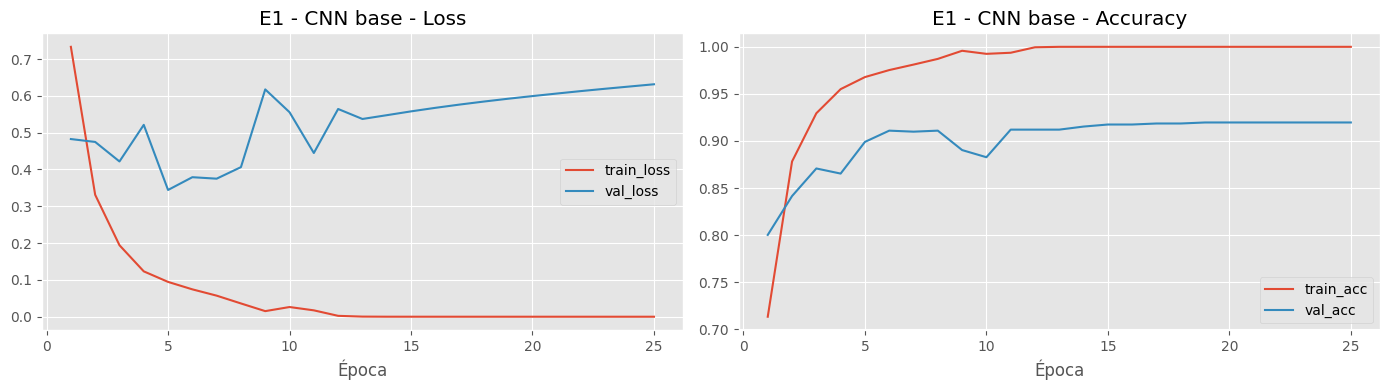

===== Diagnóstico: E1_base =====
Mejor val_accuracy: 0.9197 (época 19)
train_accuracy en esa época: 1.0000  -> gap: 0.0803
Última época -> train_acc: 1.0000 | val_acc: 0.9197 | gap: 0.0803
val_loss mínima: 0.3444 (época 5); al final: 0.6315 (cambio +0.2871)
Veredicto: SOBREAJUSTE: el train sigue mejorando pero la validación se estanca o empeora (la val_loss sube desde su mínimo y/o el gap es grande).


In [ ]:
H_e1 = entrenar(model_e1, 'E1_base', 'Desde cero', X_train, y_train, X_val, y_val, epochs=EPOCHS_EXP)
graficar_historial(H_e1, 'E1 - CNN base')
diagnosticar('E1_base')

### Análisis E1

- La accuracy de train llega al 100 %, mientras que la mejor de validación se queda en 0.9197 (época 19). Son 8 puntos de diferencia.
- La val_loss llega a su mínimo en la época 5 (0.344) y de ahí en adelante sube hasta 0.632, aunque la train_loss siga bajando casi a cero. Es el síntoma clásico de sobreajuste: la red memoriza las resonancias de entrenamiento en vez de aprender patrones generales de los tumores.

Lo positivo es que desde la primera época ya saca 0.80 en validación, muy por encima del clasificador trivial (0.29), así que sí está aprendiendo patrones útiles. El problema es la generalización.

Decisión: antes de regularizar, queremos mejorar la parte convolucional y reducir lo que llega al `Flatten`. En E2 agregamos más bloques con pooling.

## E2: Red más profunda

Cambios respecto a E1:

- Pasamos a 4 bloques convolucionales con 32 → 64 → 128 → 128 filtros. Más bloques = la red puede construir características más abstractas (bordes → texturas → formas → "masa con borde definido", "zona brillante en la base del cerebro"...), la jerarquía que vimos en clase.
- Usamos `padding="same"` para que sea el pooling el que reduce la resolución de forma controlada: 160 → 80 → 40 → 20 → 10.
- Al `Flatten` llegan 10×10×128 = 12.800 valores, mucho menos que en E1. Subimos la densa a 256 neuronas.

Hipótesis: mejor validación que E1 con bastantes menos parámetros, aunque probablemente siga sobreajustando porque todavía no hay regularización.

In [ ]:
def bloque_conv(x, filtros, batchnorm=False, dropout=0.0, l2=0.0):
    '''Bloque CONV => (BN) => RELU => CONV => (BN) => RELU => POOL => (DROPOUT).
    Lo dejamos parametrizado para reutilizarlo en E2, E3, E4...'''
    reg = regularizers.l2(l2) if l2 > 0 else None
    for _ in range(2):
        x = Conv2D(filtros, (3, 3), padding='same', kernel_regularizer=reg)(x)
        if batchnorm:
            x = BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    x = MaxPooling2D((2, 2))(x)
    if dropout > 0:
        x = Dropout(dropout)(x)
    return x


def crear_cnn(nombre, batchnorm=False, dropout_conv=0.0, dropout_dense=0.0, l2=0.0,
              augmentation=False, filtros=(32, 64, 128, 128), neuronas_densa=256):
    entradas = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = entradas
    if augmentation:
        x = crear_data_augmentation()(x)
    x = Rescaling(1. / 255)(x)

    for f in filtros:
        x = bloque_conv(x, f, batchnorm=batchnorm, dropout=dropout_conv, l2=l2)

    x = Flatten()(x)
    reg = regularizers.l2(l2) if l2 > 0 else None
    x = Dense(neuronas_densa, kernel_regularizer=reg)(x)
    if batchnorm:
        x = BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    if dropout_dense > 0:
        x = Dropout(dropout_dense)(x)
    salida = Dense(NUM_CLASES, activation='softmax')(x)
    return Model(entradas, salida, name=nombre)


model_e2 = crear_cnn('E2_profunda')
model_e2.summary()

Model: "E2_profunda"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 160, 160, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 80, 80, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 40, 40, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 20, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 20, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     3,277,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 256)            │             

 Total params: 3,860,260 (14.73 MB)

 Trainable params: 3,860,260 (14.73 MB)

 Non-trainable params: 0 (0.00 B)

[INFO] E2_profunda: 3,860,260 parámetros (3,860,260 entrenables)
Epoch 1/25
135/135 - 57s - 425ms/step - accuracy: 0.5463 - loss: 1.0103 - val_accuracy: 0.7264 - val_loss: 0.6661
Epoch 2/25
135/135 - 10s - 73ms/step - accuracy: 0.7289 - loss: 0.6634 - val_accuracy: 0.7068 - val_loss: 0.7059
Epoch 3/25
135/135 - 10s - 73ms/step - accuracy: 0.7694 - loss: 0.5550 - val_accuracy: 0.7915 - val_loss: 0.4774
Epoch 4/25
135/135 - 10s - 72ms/step - accuracy: 0.8230 - loss: 0.4506 - val_accuracy: 0.8035 - val_loss: 0.4443
Epoch 5/25
135/135 - 10s - 72ms/step - accuracy: 0.8628 - loss: 0.3544 - val_accuracy: 0.8339 - val_loss: 0.4074
Epoch 6/25
135/135 - 10s - 71ms/step - accuracy: 0.8756 - loss: 0.3130 - val_accuracy: 0.8697 - val_loss: 0.3574
Epoch 7/25
135/135 - 10s - 71ms/step - accuracy: 0.8992 - loss: 0.2503 - val_accuracy: 0.8567 - val_loss: 0.3876
Epoch 8/25
135/135 - 10s - 71ms/step - accuracy: 0.9159 - loss: 0.2224 - val_accuracy: 0.8762 - val_loss: 0.3657
Epoch 9/25
135/135 - 10s - 72m

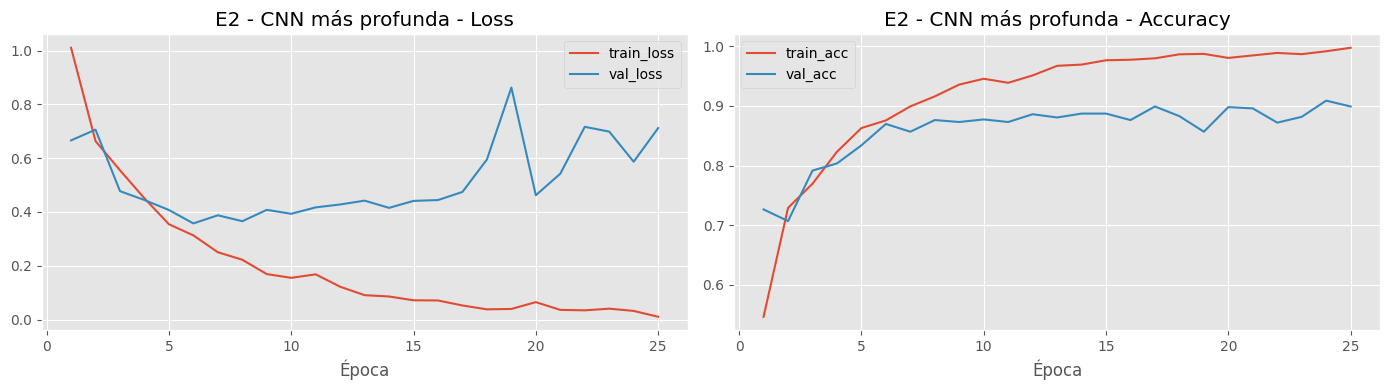

===== Diagnóstico: E2_profunda =====
Mejor val_accuracy: 0.9088 (época 24)
train_accuracy en esa época: 0.9916  -> gap: 0.0828
Última época -> train_acc: 0.9974 | val_acc: 0.8990 | gap: 0.0984
val_loss mínima: 0.3574 (época 6); al final: 0.7118 (cambio +0.3543)
Veredicto: SOBREAJUSTE: el train sigue mejorando pero la validación se estanca o empeora (la val_loss sube desde su mínimo y/o el gap es grande).


In [ ]:
H_e2 = entrenar(model_e2, 'E2_profunda', 'Desde cero', X_train, y_train, X_val, y_val, epochs=EPOCHS_EXP)
graficar_historial(H_e2, 'E2 - CNN más profunda')
diagnosticar('E2_profunda')

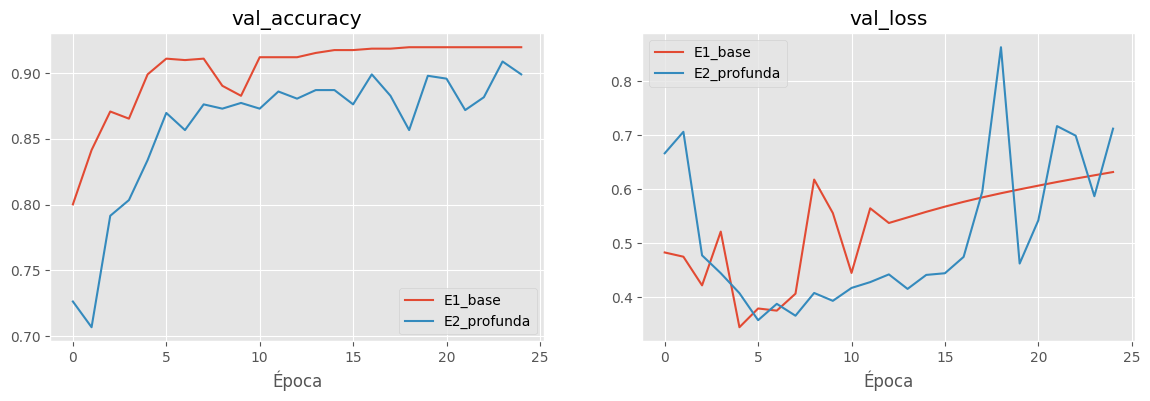

E1 -> mejor val_acc: 0.9197 | parámetros: 11,281,060
E2 -> mejor val_acc: 0.9088 | parámetros: 3,860,260


In [ ]:
# Comparación directa E1 vs E2 en validación
plt.figure(figsize=(14, 4))
for i, metrica in enumerate(['val_accuracy', 'val_loss']):
    plt.subplot(1, 2, i + 1)
    for n in ['E1_base', 'E2_profunda']:
        plt.plot(historiales[n][metrica], label=n)
    plt.title(metrica)
    plt.xlabel("Época")
    plt.legend()
plt.show()

print(f"E1 -> mejor val_acc: {val_acc_de('E1_base'):.4f} | parámetros: {model_e1.count_params():,}")
print(f"E2 -> mejor val_acc: {val_acc_de('E2_profunda'):.4f} | parámetros: {model_e2.count_params():,}")

### Análisis E2

- E2 tiene 3,86 M de parámetros contra 11,28 M de E1, casi tres veces menos, porque al `Flatten` ya no le llega un tensor gigante.
- Pero en validación no mejoró: 0.9088 contra 0.9197 de E1. Esperábamos que la red más profunda generalizara mejor por sí sola, y no fue así. La diferencia es de 1 punto (unas 10 imágenes de validación), así que más bien diríamos que quedaron parecidas.
- El sobreajuste sigue igual: el train llega a 0.99-1.00, la val_loss tiene su mínimo en la época 6 (0.357) y al final sube a 0.712.

Decisión: nos quedamos con los 4 bloques porque logra lo mismo con un tercio de los parámetros, y atacamos el sobreajuste con las técnicas de regularización del curso, empezando por Batch Normalization + Dropout (E3).

## E3: Batch Normalization + Dropout

Como en el ejemplo de CIFAR-10 de clase, agregamos:

- Batch Normalization después de cada convolución (antes de la ReLU): normaliza las activaciones de cada batch, estabiliza el entrenamiento y permite converger más rápido. Además tiene un pequeño efecto regularizador. Nos pareció especialmente útil aquí porque las resonancias tienen contrastes muy distintos entre sí.
- Dropout de 0.25 al final de cada bloque convolucional y 0.5 antes de la salida: en cada paso de entrenamiento "apaga" neuronas al azar, para que la red no dependa de unas pocas para memorizar imágenes.

Problema que queremos resolver: el sobreajuste de E2.

Hipótesis: menor gap train-validación, una val_loss que sube menos (o no sube) y mejor val_accuracy. La accuracy de train va a crecer más lento, que es normal con dropout.

[INFO] E3_bn_dropout: 3,864,100 parámetros (3,862,180 entrenables)
Epoch 1/25
135/135 - 53s - 390ms/step - accuracy: 0.7163 - loss: 0.7602 - val_accuracy: 0.4137 - val_loss: 1.4338
Epoch 2/25
135/135 - 11s - 85ms/step - accuracy: 0.8093 - loss: 0.5013 - val_accuracy: 0.2877 - val_loss: 2.1898
Epoch 3/25
135/135 - 12s - 86ms/step - accuracy: 0.8631 - loss: 0.3709 - val_accuracy: 0.4419 - val_loss: 2.0525
Epoch 4/25
135/135 - 12s - 86ms/step - accuracy: 0.9008 - loss: 0.2693 - val_accuracy: 0.7068 - val_loss: 0.9427
Epoch 5/25
135/135 - 12s - 85ms/step - accuracy: 0.9252 - loss: 0.2211 - val_accuracy: 0.9131 - val_loss: 0.2522
Epoch 6/25
135/135 - 11s - 84ms/step - accuracy: 0.9404 - loss: 0.1665 - val_accuracy: 0.9186 - val_loss: 0.2336
Epoch 7/25
135/135 - 11s - 84ms/step - accuracy: 0.9488 - loss: 0.1369 - val_accuracy: 0.9338 - val_loss: 0.1929
Epoch 8/25
135/135 - 11s - 85ms/step - accuracy: 0.9590 - loss: 0.1128 - val_accuracy: 0.8198 - val_loss: 0.5093
Epoch 9/25
135/135 - 11s - 8

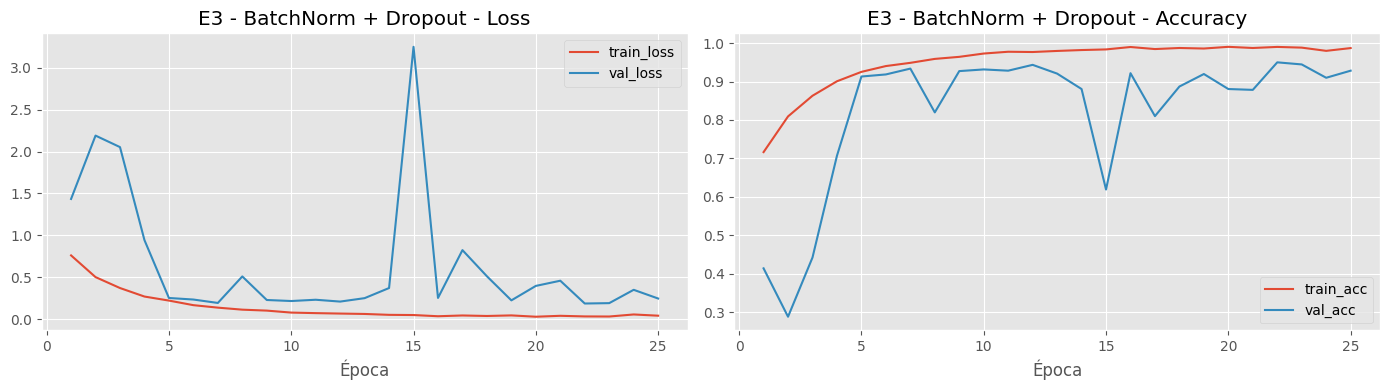

===== Diagnóstico: E3_bn_dropout =====
Mejor val_accuracy: 0.9501 (época 22)
train_accuracy en esa época: 0.9902  -> gap: 0.0402
Última época -> train_acc: 0.9872 | val_acc: 0.9283 | gap: 0.0589
val_loss mínima: 0.1862 (época 22); al final: 0.2458 (cambio +0.0596)
Veredicto: SOBREAJUSTE: el train sigue mejorando pero la validación se estanca o empeora (la val_loss sube desde su mínimo y/o el gap es grande).


In [ ]:
model_e3 = crear_cnn('E3_bn_dropout', batchnorm=True, dropout_conv=0.25, dropout_dense=0.5)
H_e3 = entrenar(model_e3, 'E3_bn_dropout', 'Desde cero', X_train, y_train, X_val, y_val, epochs=EPOCHS_EXP)
graficar_historial(H_e3, 'E3 - BatchNorm + Dropout')
diagnosticar('E3_bn_dropout')

### Análisis E3

Este fue el salto más grande de toda la estrategia: la mejor val_accuracy pasa de 0.9088 (E2) a 0.9501, y la val_loss mínima baja de 0.357 a 0.186. El gap train-validación en la mejor época baja de 8,3 a 4,0 puntos.

Lo que sí llama la atención es lo "nerviosa" que es la curva de validación: en las primeras épocas sale 0.41, 0.44, 0.71, e incluso después de la época 15 salta entre 0.62 y 0.95 de una época a otra. Pasa con BatchNorm porque en entrenamiento la BN usa las estadísticas de cada batch y en validación usa medias móviles que todavía se están ajustando. Esto tiene una consecuencia práctica que tuvimos en cuenta: el "mejor valor de validación" de un experimento depende bastante de la época en que cayó, así que las diferencias de 1 punto entre experimentos no hay que tomarlas muy en serio.

El diagnóstico automático dice "sobreajuste" porque mira la última época (gap de 5,9 puntos), pero comparado con E1 y E2 está mucho mejor controlado.

Decisión: probamos si sumar regularización L2 sobre los pesos ayuda a generalizar todavía más.

## E4: E3 + regularización L2 (*weight regularization*)

Agregamos `kernel_regularizer=l2(1e-4)` en todas las `Conv2D` y en la `Dense`. La L2 suma a la pérdida un término proporcional al cuadrado de los pesos: la red "paga" por tener pesos grandes y tiende a soluciones más simples, que suelen generalizar mejor.

Usamos `1e-4` y no `1e-3` (el valor del ejemplo de clase con capas densas) porque aquí hay muchas más capas regularizadas, y con un valor más alto la penalización dominaría la pérdida.

Hipótesis: algo menos de sobreajuste que E3. Como ya hay BN y Dropout, la mejora puede ser pequeña o nula; por eso decidimos con el resultado.

> Nota: la `loss` de E4 incluye el término de regularización, así que su valor absoluto no se puede comparar directamente con E3. Para comparar nos fijamos en la val_accuracy.

[INFO] E4_bn_dropout_l2: 3,864,100 parámetros (3,862,180 entrenables)
Epoch 1/25
135/135 - 41s - 305ms/step - accuracy: 0.7091 - loss: 0.9053 - val_accuracy: 0.2953 - val_loss: 1.9467
Epoch 2/25
135/135 - 12s - 85ms/step - accuracy: 0.8095 - loss: 0.6550 - val_accuracy: 0.2921 - val_loss: 1.8640
Epoch 3/25
135/135 - 12s - 87ms/step - accuracy: 0.8579 - loss: 0.5322 - val_accuracy: 0.6764 - val_loss: 1.0379
Epoch 4/25
135/135 - 12s - 87ms/step - accuracy: 0.8861 - loss: 0.4605 - val_accuracy: 0.7818 - val_loss: 0.7597
Epoch 5/25
135/135 - 12s - 85ms/step - accuracy: 0.9150 - loss: 0.3948 - val_accuracy: 0.9088 - val_loss: 0.4126
Epoch 6/25
135/135 - 11s - 85ms/step - accuracy: 0.9367 - loss: 0.3528 - val_accuracy: 0.9142 - val_loss: 0.4304
Epoch 7/25
135/135 - 11s - 85ms/step - accuracy: 0.9390 - loss: 0.3579 - val_accuracy: 0.6884 - val_loss: 1.6182
Epoch 8/25
135/135 - 12s - 85ms/step - accuracy: 0.9539 - loss: 0.3188 - val_accuracy: 0.9370 - val_loss: 0.3719
Epoch 9/25
135/135 - 12s 

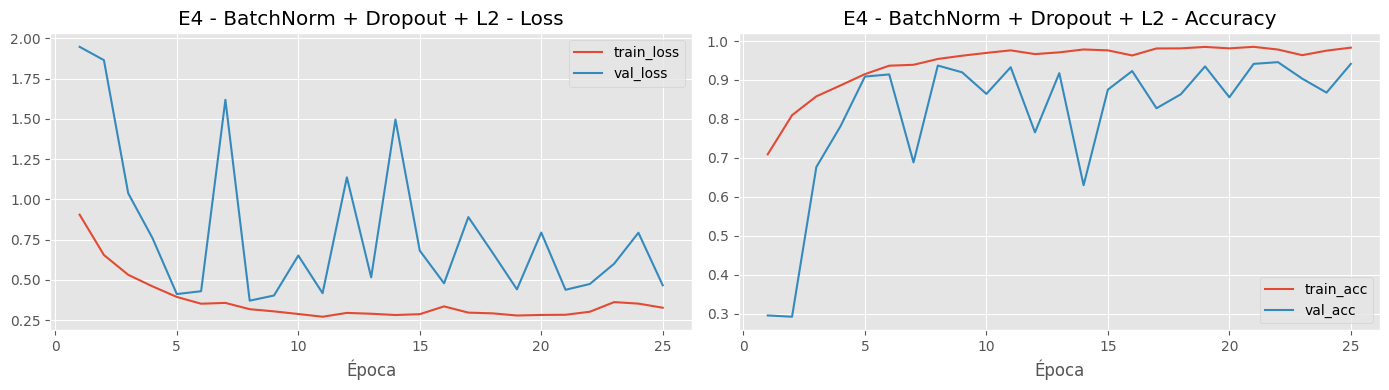

===== Diagnóstico: E4_bn_dropout_l2 =====
Mejor val_accuracy: 0.9457 (época 22)
train_accuracy en esa época: 0.9781  -> gap: 0.0324
Última época -> train_acc: 0.9830 | val_acc: 0.9414 | gap: 0.0416
val_loss mínima: 0.3719 (época 8); al final: 0.4675 (cambio +0.0956)
Veredicto: BUEN BALANCE: train y validación avanzan juntos, sin sobreajuste marcado.


In [ ]:
model_e4 = crear_cnn('E4_bn_dropout_l2', batchnorm=True, dropout_conv=0.25, dropout_dense=0.5, l2=1e-4)
H_e4 = entrenar(model_e4, 'E4_bn_dropout_l2', 'Desde cero', X_train, y_train, X_val, y_val, epochs=EPOCHS_EXP)
graficar_historial(H_e4, 'E4 - BatchNorm + Dropout + L2')
diagnosticar('E4_bn_dropout_l2')

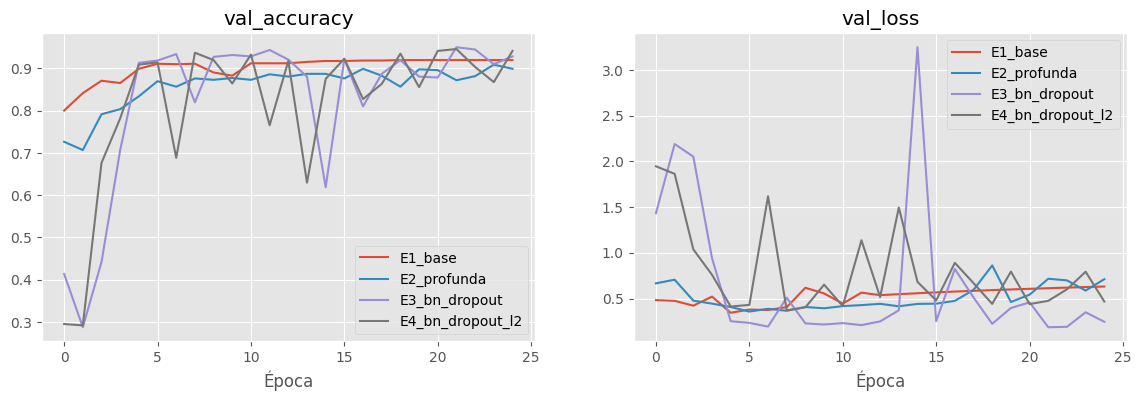

,experimento,mejor_epoca,train_acc,val_acc,gap_acc,params_total,tiempo_s
0,E1_base,19,1.0000,0.9197,0.0803,11281060,220.0367
1,E2_profunda,24,0.9916,0.9088,0.0828,3860260,289.8158
2,E3_bn_dropout,22,0.9902,0.9501,0.0402,3864100,329.0752
3,E4_bn_dropout_l2,22,0.9781,0.9457,0.0324,3864100,318.6499


In [ ]:
# Comparación de los 4 experimentos sin augmentation
plt.figure(figsize=(14, 4))
for i, metrica in enumerate(['val_accuracy', 'val_loss']):
    plt.subplot(1, 2, i + 1)
    for n in ['E1_base', 'E2_profunda', 'E3_bn_dropout', 'E4_bn_dropout_l2']:
        plt.plot(historiales[n][metrica], label=n)
    plt.title(metrica)
    plt.xlabel("Época")
    plt.legend()
plt.show()

pd.DataFrame(resultados)[['experimento', 'mejor_epoca', 'train_acc', 'val_acc', 'gap_acc', 'params_total', 'tiempo_s']].round(4)

In [ ]:
# Decisión basada en validación: ¿nos quedamos con L2 o no?
USAR_L2 = val_acc_de('E4_bn_dropout_l2') > val_acc_de('E3_bn_dropout')
L2_ELEGIDO = 1e-4 if USAR_L2 else 0.0
print(f"E3 (sin L2) mejor val_acc: {val_acc_de('E3_bn_dropout'):.4f}")
print(f"E4 (con L2) mejor val_acc: {val_acc_de('E4_bn_dropout_l2'):.4f}")
print("Decisión ->", "mantener L2 en los siguientes experimentos" if USAR_L2 else "quitar L2 (no aportó en validación)")

E3 (sin L2) mejor val_acc: 0.9501
E4 (con L2) mejor val_acc: 0.9457
Decisión -> quitar L2 (no aportó en validación)


### Análisis E3 vs E4

E4, con L2, sacó 0.9457, un poco menos que E3 (0.9501), así que la celda anterior la descartó. No quisimos elegir "a mano" para que la decisión salga directamente del experimento.

La val_loss de E4 se ve más alta (mínimo 0.372), pero ojo: en E4 la loss incluye la penalización L2, así que no es directamente comparable con la de E3. Por eso decidimos con la accuracy. La L2 sí redujo un poco el gap (3,2 puntos contra 4,0), pero eso no se tradujo en mejor validación: con BN + Dropout ya había bastante regularización.

El problema de fondo sigue siendo que unas 4.300 imágenes de entrenamiento son pocas para una CNN desde cero: la red termina viendo las mismas resonancias una y otra vez.

Decisión: atacar justamente eso con data augmentation, para que en cada época la red vea versiones distintas de las imágenes.

## E5: + Data augmentation + EarlyStopping

Sobre la mejor configuración hasta ahora (E3 o E4 según la decisión de arriba) agregamos el bloque de data augmentation al inicio del modelo.

Con augmentation la red tarda más en aprender (cada época es "más difícil"), así que subimos el máximo a 60 épocas. Para no entrenar de más usamos EarlyStopping (el callback que mencionamos en clase para paliar el sobreajuste) sobre la `val_loss`, con paciencia de 8 épocas y `restore_best_weights=True` para quedarnos con los pesos de la mejor época.

Problema que queremos resolver: el sobreajuste que queda por tener pocos datos.

Hipótesis: curvas de train y validación mucho más pegadas y la mejor val_accuracy hasta ahora.

[INFO] E5_augmentation: 3,864,100 parámetros (3,862,180 entrenables)
Epoch 1/60
135/135 - 40s - 295ms/step - accuracy: 0.6537 - loss: 0.9543 - val_accuracy: 0.2562 - val_loss: 1.3994
Epoch 2/60
135/135 - 23s - 169ms/step - accuracy: 0.7366 - loss: 0.7271 - val_accuracy: 0.0651 - val_loss: 2.3570
Epoch 3/60
135/135 - 23s - 168ms/step - accuracy: 0.7771 - loss: 0.5922 - val_accuracy: 0.4387 - val_loss: 1.8168
Epoch 4/60
135/135 - 23s - 170ms/step - accuracy: 0.8002 - loss: 0.5233 - val_accuracy: 0.6526 - val_loss: 0.8149
Epoch 5/60
135/135 - 23s - 169ms/step - accuracy: 0.8170 - loss: 0.4714 - val_accuracy: 0.5559 - val_loss: 1.5175
Epoch 6/60
135/135 - 23s - 169ms/step - accuracy: 0.8419 - loss: 0.4135 - val_accuracy: 0.2465 - val_loss: 3.7679
Epoch 7/60
135/135 - 23s - 169ms/step - accuracy: 0.8510 - loss: 0.3855 - val_accuracy: 0.6374 - val_loss: 0.9672
Epoch 8/60
135/135 - 23s - 169ms/step - accuracy: 0.8666 - loss: 0.3411 - val_accuracy: 0.7557 - val_loss: 0.6904
Epoch 9/60
135/135 

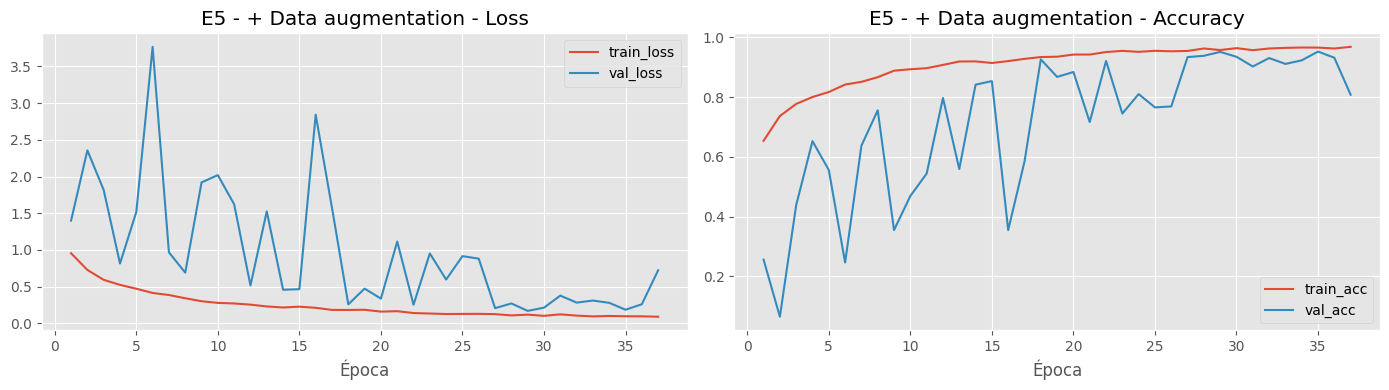

===== Diagnóstico: E5_augmentation =====
Mejor val_accuracy: 0.9522 (época 35)
train_accuracy en esa época: 0.9655  -> gap: 0.0133
Última época -> train_acc: 0.9681 | val_acc: 0.8078 | gap: 0.1603
val_loss mínima: 0.1691 (época 29); al final: 0.7223 (cambio +0.5532)
Veredicto: SOBREAJUSTE: el train sigue mejorando pero la validación se estanca o empeora (la val_loss sube desde su mínimo y/o el gap es grande).


In [ ]:
def callback_early_stopping(paciencia):
    return EarlyStopping(monitor='val_loss', patience=paciencia, restore_best_weights=True, verbose=1)


model_e5 = crear_cnn('E5_augmentation', batchnorm=True, dropout_conv=0.25, dropout_dense=0.5,
                     l2=L2_ELEGIDO, augmentation=True)
H_e5 = entrenar(model_e5, 'E5_augmentation', 'Desde cero', X_train, y_train, X_val, y_val,
                epochs=60, callbacks=[callback_early_stopping(8)])
graficar_historial(H_e5, 'E5 - + Data augmentation')
diagnosticar('E5_augmentation')

### Análisis E5

- El gap train-validación casi desaparece: en la mejor época es de 1,3 puntos (train 0.9655, validación 0.9522), cuando en E3 era de 4,0. La red ya casi no memoriza.
- La mejor val_accuracy subió, pero poco: 0.9522 contra 0.9501 de E3. Esperábamos más. Nuestra interpretación es que con BN + Dropout esta arquitectura ya estaba cerca de su techo a 160×160, y el augmentation aquí se nota más en el gap que en el valor máximo.
- Costo: 37 épocas (el EarlyStopping paró en la 37 y restauró la 29) y 14,7 minutos, casi tres veces lo de E3.
- La validación sigue muy inestable: en la última época cayó a 0.81. El diagnóstico automático marca "sobreajuste" porque mira esa última época, pero como el EarlyStopping restaura los pesos de la mejor val_loss, el modelo que queda es el bueno.

Un dato que encontramos al correr el notebook dos veces: en la primera ejecución, con el mismo código, E5 llegó a 0.979 en validación, y en esta a 0.952. En GPU el entrenamiento no es 100 % determinista, y con una validación tan nerviosa la diferencia entre corridas llega a unos 2-3 puntos. Es otra razón para no darle mucho peso a diferencias de 1 punto.

Decisión: la configuración base ya está. Como último ajuste queremos ver el efecto de la tasa de aprendizaje.

## E6: Learning rate más bajo

Mismo modelo que E5, pero con `Adam(learning_rate=3e-4)` en vez de `1e-3`.

Hipótesis: con un lr más bajo los pasos son más pequeños; la convergencia es más lenta pero más estable, y a veces llega a un mínimo un poco mejor. Si el lr de E5 ya era adecuado, el resultado debería ser parecido.

[INFO] E6_aug_lr_bajo: 3,864,100 parámetros (3,862,180 entrenables)
Epoch 1/60
135/135 - 30s - 223ms/step - accuracy: 0.6262 - loss: 0.9619 - val_accuracy: 0.2888 - val_loss: 2.8421
Epoch 2/60
135/135 - 23s - 171ms/step - accuracy: 0.7033 - loss: 0.7751 - val_accuracy: 0.2888 - val_loss: 2.4521
Epoch 3/60
135/135 - 23s - 170ms/step - accuracy: 0.7324 - loss: 0.6811 - val_accuracy: 0.3127 - val_loss: 1.6287
Epoch 4/60
135/135 - 23s - 170ms/step - accuracy: 0.7664 - loss: 0.6139 - val_accuracy: 0.6135 - val_loss: 0.8855
Epoch 5/60
135/135 - 23s - 170ms/step - accuracy: 0.7934 - loss: 0.5420 - val_accuracy: 0.6830 - val_loss: 0.8770
Epoch 6/60
135/135 - 23s - 169ms/step - accuracy: 0.8093 - loss: 0.4925 - val_accuracy: 0.8284 - val_loss: 0.4945
Epoch 7/60
135/135 - 23s - 170ms/step - accuracy: 0.8286 - loss: 0.4502 - val_accuracy: 0.7448 - val_loss: 0.7792
Epoch 8/60
135/135 - 23s - 170ms/step - accuracy: 0.8388 - loss: 0.4137 - val_accuracy: 0.5983 - val_loss: 1.5571
Epoch 9/60
135/135 -

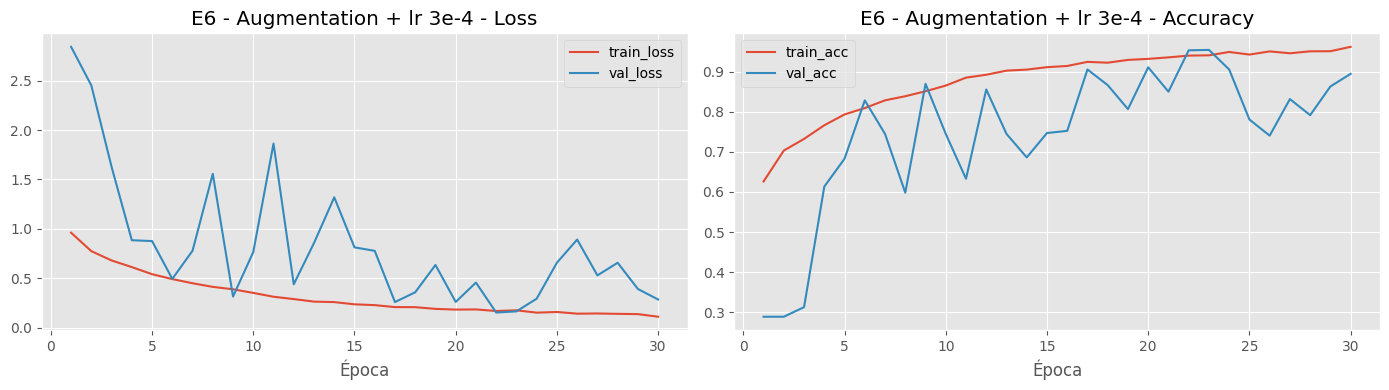

===== Diagnóstico: E6_aug_lr_bajo =====
Mejor val_accuracy: 0.9544 (época 23)
train_accuracy en esa época: 0.9408  -> gap: -0.0135
Última época -> train_acc: 0.9620 | val_acc: 0.8947 | gap: 0.0674
val_loss mínima: 0.1539 (época 22); al final: 0.2859 (cambio +0.1320)
Veredicto: SOBREAJUSTE: el train sigue mejorando pero la validación se estanca o empeora (la val_loss sube desde su mínimo y/o el gap es grande).


In [ ]:
tf.keras.utils.set_random_seed(SEED)
model_e6 = crear_cnn('E6_aug_lr_bajo', batchnorm=True, dropout_conv=0.25, dropout_dense=0.5,
                     l2=L2_ELEGIDO, augmentation=True)
H_e6 = entrenar(model_e6, 'E6_aug_lr_bajo', 'Desde cero', X_train, y_train, X_val, y_val,
                epochs=60, learning_rate=3e-4, callbacks=[callback_early_stopping(8)])
graficar_historial(H_e6, 'E6 - Augmentation + lr 3e-4')
diagnosticar('E6_aug_lr_bajo')

## Resumen de la Estrategia 1 y elección del modelo desde cero

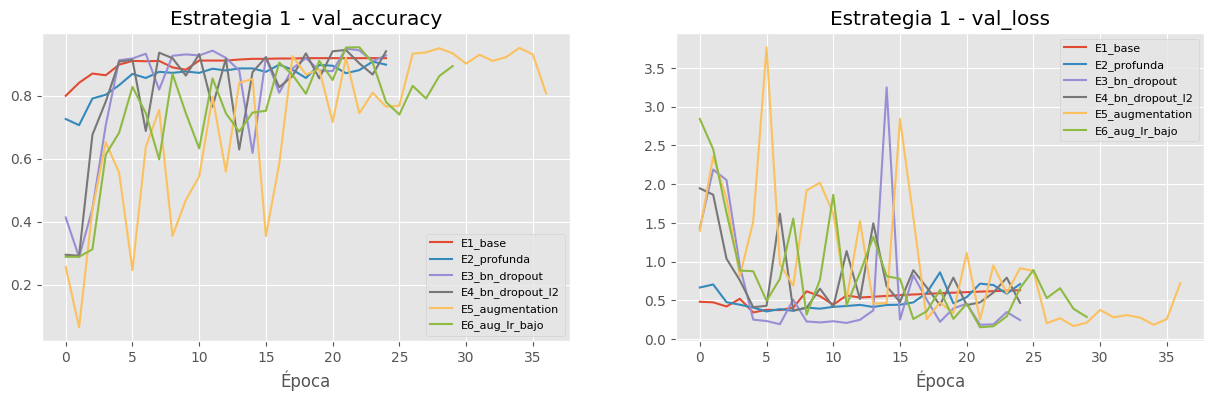

,experimento,epocas,mejor_epoca,train_acc,val_acc,gap_acc,val_loss_min,params_total,tiempo_min
0,E1_base,25,19,1.0000,0.9197,0.0803,0.3444,11281060,3.6673
1,E2_profunda,25,24,0.9916,0.9088,0.0828,0.3574,3860260,4.8303
2,E3_bn_dropout,25,22,0.9902,0.9501,0.0402,0.1862,3864100,5.4846
3,E4_bn_dropout_l2,25,22,0.9781,0.9457,0.0324,0.3719,3864100,5.3108
4,E5_augmentation,37,35,0.9655,0.9522,0.0133,0.1691,3864100,14.6949
5,E6_aug_lr_bajo,30,23,0.9408,0.9544,-0.0135,0.1539,3864100,11.9191


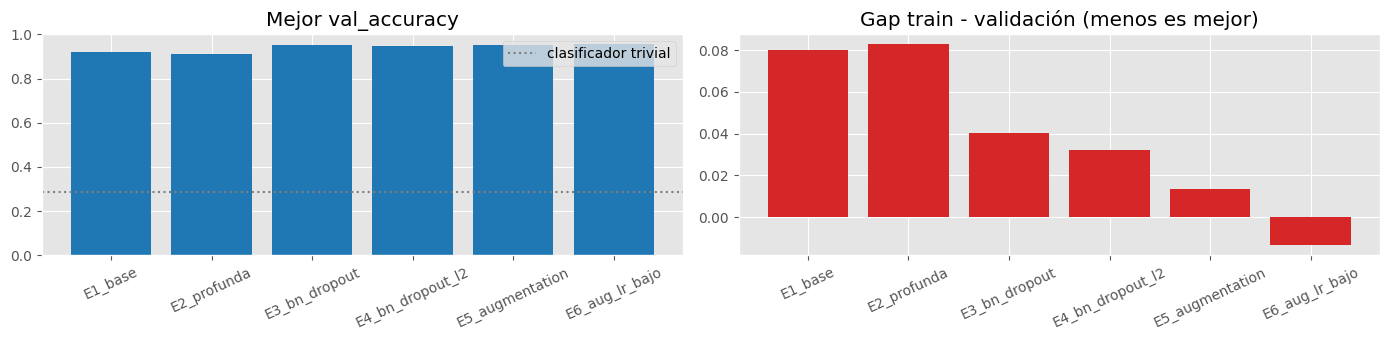

In [ ]:
exp_scratch = ['E1_base', 'E2_profunda', 'E3_bn_dropout', 'E4_bn_dropout_l2', 'E5_augmentation', 'E6_aug_lr_bajo']

plt.figure(figsize=(15, 4))
for i, metrica in enumerate(['val_accuracy', 'val_loss']):
    plt.subplot(1, 2, i + 1)
    for n in exp_scratch:
        plt.plot(historiales[n][metrica], label=n)
    plt.title(f"Estrategia 1 - {metrica}")
    plt.xlabel("Época")
    plt.legend(fontsize=8)
plt.show()

df_scratch = pd.DataFrame([r for r in resultados if r['experimento'] in exp_scratch])
df_scratch['tiempo_min'] = df_scratch['tiempo_s'] / 60
display(df_scratch[['experimento', 'epocas', 'mejor_epoca', 'train_acc', 'val_acc', 'gap_acc',
                    'val_loss_min', 'params_total', 'tiempo_min']].round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].bar(df_scratch['experimento'], df_scratch['val_acc'], color='tab:blue')
axes[0].axhline(acc_trivial_val, color='gray', linestyle=':', label='clasificador trivial')
axes[0].set_ylim(0, 1.0)
axes[0].set_title("Mejor val_accuracy")
axes[0].legend()
axes[1].bar(df_scratch['experimento'], df_scratch['gap_acc'], color='tab:red')
axes[1].set_title("Gap train - validación (menos es mejor)")
for ax in axes:
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

In [ ]:
# Escogemos el mejor modelo desde cero SOLO con validación (el test todavía no se toca)
modelos_scratch = {'E1_base': model_e1, 'E2_profunda': model_e2, 'E3_bn_dropout': model_e3,
                   'E4_bn_dropout_l2': model_e4, 'E5_augmentation': model_e5, 'E6_aug_lr_bajo': model_e6}
MEJOR_SCRATCH = max(exp_scratch, key=val_acc_de)
mejor_modelo_scratch = modelos_scratch[MEJOR_SCRATCH]
print(f"Mejor modelo desde cero: {MEJOR_SCRATCH} (val_acc = {val_acc_de(MEJOR_SCRATCH):.4f})")

mejor_modelo_scratch.save(os.path.join(BASE_FOLDER, 'mejor_cnn_desde_cero.keras'))

Mejor modelo desde cero: E6_aug_lr_bajo (val_acc = 0.9544)


### Conclusiones de la Estrategia 1

| Experimento | Cambio | Mejor val_acc | Gap train-val |
|---|---|---|---|
| E1 | CNN base (2 bloques) | 0.9197 | 8,0 pp |
| E2 | 4 bloques | 0.9088 | 8,3 pp |
| E3 | + BatchNorm + Dropout | 0.9501 | 4,0 pp |
| E4 | + L2 | 0.9457 | 3,2 pp |
| E5 | + Data augmentation + EarlyStopping (sin L2) | 0.9522 | 1,3 pp |
| E6 | + lr = 3e-4 | 0.9544 | -1,4 pp |

El camino que seguimos:

1. E1 mostró que una CNN sencilla aprende, pero sobreajusta muy rápido y gasta casi todos sus parámetros en la capa densa.
2. E2 logró prácticamente lo mismo con un tercio de los parámetros, pero no generalizó mejor por ser más profunda.
3. E3 (BatchNorm + Dropout) fue el cambio que más ayudó: +4 puntos y la val_loss bajó a la mitad. La L2 (E4) no aportó.
4. E5 (augmentation) casi eliminó el gap, y E6, con un learning rate más bajo, dio la mejor val_accuracy (0.9544) y la val_loss más baja (0.154). Es el modelo que elegimos. Que la validación quede por encima del train es normal aquí: el Dropout y el augmentation solo actúan en entrenamiento, así que el train se mide sobre imágenes "más difíciles".

E3, E5 y E6 están separados por menos de medio punto, que está dentro de la variación normal entre corridas. Escogemos E6 porque además de tener la mejor accuracy tiene la menor val_loss y el menor gap, o sea, es el más equilibrado.

Algo que aprendimos haciendo esto: la regularización no "sube la accuracy" por arte de magia. Lo que hace es permitir que la red entrene más tiempo sin memorizar. Lo que más se nota es cuánto se cierra la distancia entre train y validación, más que el valor máximo.

# 6. Estrategia 2: Redes preentrenadas (*transfer learning* y *fine-tuning*)

Ahora usamos redes entrenadas en ImageNet (1,2 millones de fotos, 1.000 clases). Como vimos en la sesión 3, la parte convolucional ya aprendió a detectar bordes, texturas, formas y partes de objetos, y eso se puede reutilizar en otro problema.

La pregunta interesante de este proyecto: ImageNet no tiene ni una sola resonancia magnética. Las primeras capas (bordes, texturas) seguramente sí sirven, pero las últimas están especializadas en cosas como "hocico de perro" o "rueda de carro". Por eso esperamos que aquí el fine-tuning sea mucho más importante que en un problema de fotos normales.

Escogimos dos arquitecturas vistas en clase, bastante distintas entre sí:

- VGG16: la de los ejemplos de clase. Arquitectura "clásica" de bloques de convoluciones 3×3 + max pooling. Pesada (~14,7 M de parámetros en la base).
- MobileNetV2: la del ejemplo de la sesión 3. Diseñada para ser ligera (~2,3 M de parámetros en la base) con convoluciones *depthwise separable* y bloques residuales invertidos. Queremos ver si con muchos menos parámetros puede igualar a VGG16.

Para cada una hacemos los mismos pasos, para que la comparación sea justa:

| Paso | Qué hacemos | Capas entrenables |
|---|---|---|
| P1 | *Transfer learning* puro: base congelada + top nuevo | Solo el top |
| P2 | Igual que P1 + *data augmentation* | Solo el top |
| P3 | *Fine-tuning* nivel 1: descongelamos el último bloque de la base (lr muy bajo) | Top + último bloque |
| P4 | *Fine-tuning* nivel 2: descongelamos un bloque más (descongelado progresivo) | Top + 2 últimos bloques |

Top model (el mismo para las dos): `GlobalAveragePooling2D → Dense(256, relu) → Dropout(0.5) → Dense(4, softmax)`. Usamos `GlobalAveragePooling2D` en vez de `Flatten` porque, como vimos en clase, resume cada mapa de características en un número y reduce mucho los parámetros del top, lo que también ayuda a no sobreajustar.

## 6.1 Preprocesamiento específico de cada red

Cada red preentrenada espera la entrada normalizada igual que cuando la entrenaron en ImageNet (el "IMPORTANTE" de los notebooks de clase):

- VGG16 (`vgg16.preprocess_input`): pasa de RGB a BGR y resta la media de ImageNet de cada canal.
- MobileNetV2 (`mobilenet_v2.preprocess_input`): escala los píxeles al rango [-1, 1].

Si en vez de esto dividiéramos entre 255, las características de la base no se parecerían a las que aprendió y el transfer learning funcionaría peor.

Para no tener las dos versiones en memoria a la vez, preparamos los datos de cada red justo antes de usarla y después borramos lo que ya no necesitamos.

In [ ]:
def preparar_datos(funcion_preprocess):
    '''Aplica el preprocess_input de la red (devuelve copias en float32).'''
    return (funcion_preprocess(X_train.astype('float32')),
            funcion_preprocess(X_val.astype('float32')),
            funcion_preprocess(X_test.astype('float32')))


# Rango de los píxeles DESPUÉS del preprocess_input de cada red (lo imprimimos en las celdas de abajo).
# Se lo pasamos al data augmentation para que RandomContrast no recorte los valores negativos.
RANGO_PREPROCESS = {'VGG16': (-123.68, 151.061), 'MobileNetV2': (-1.0, 1.0)}


def crear_modelo_preentrenado(arquitectura, augmentation=False):
    '''Crea base preentrenada (congelada) + top model. Devuelve (modelo, base).'''
    if arquitectura == 'VGG16':
        base = VGG16(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    else:
        base = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False      # TRANSFER LEARNING: no se modifican los pesos de la base

    entradas = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = entradas
    if augmentation:
        x = crear_data_augmentation(RANGO_PREPROCESS[arquitectura])(x)
    # training=False hace que las BatchNorm de la base (MobileNetV2 tiene muchas) sigan usando
    # las estadísticas de ImageNet, incluso cuando después descongelemos capas para el fine-tuning
    x = base(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    salida = Dense(NUM_CLASES, activation='softmax')(x)
    return Model(entradas, salida, name=f"{arquitectura}_transfer"), base


def descongelar_desde(base, nombre_capa=None, ultimas_n=None):
    '''Fine-tuning: congela toda la base y descongela desde `nombre_capa` (o las últimas n capas).'''
    base.trainable = True
    if nombre_capa is not None:
        congelar = True
        for capa in base.layers:
            if capa.name == nombre_capa:
                congelar = False
            capa.trainable = not congelar
    else:
        for capa in base.layers[:-ultimas_n]:
            capa.trainable = False
        for capa in base.layers[-ultimas_n:]:
            capa.trainable = True
    # Las BatchNorm se dejan congeladas para no romper lo aprendido (batches pequeños = estadísticas ruidosas)
    for capa in base.layers:
        if isinstance(capa, BatchNormalization):
            capa.trainable = False
    n_entrenables = sum(1 for c in base.layers if c.trainable)
    print(f"Capas entrenables de la base: {n_entrenables} de {len(base.layers)}")


def graficar_tl_ft(nombres, titulo):
    '''Junta los historiales de transfer learning + fine-tuning en una sola gráfica.'''
    h_total = {k: [] for k in ['loss', 'val_loss', 'accuracy', 'val_accuracy']}
    cortes = []
    for n in nombres:
        for k in h_total:
            h_total[k] += list(historiales[n][k])
        cortes.append(len(h_total['loss']))
    epocas = np.arange(1, len(h_total['loss']) + 1)
    plt.style.use("ggplot")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for ax, (a, b, etiqueta) in zip(axes, [('loss', 'val_loss', 'train_loss'),
                                           ('accuracy', 'val_accuracy', 'train_acc')]):
        ax.plot(epocas, h_total[a], label=etiqueta)
        ax.plot(epocas, h_total[b], label=b)
        for c, n in zip(cortes[:-1], nombres[1:]):
            ax.axvline(c + 0.5, color='gray', linestyle='--')
            ax.text(c + 0.7, ax.get_ylim()[1], n.split('_', 1)[1], fontsize=8, va='top')
        ax.set_xlabel("Época (acumulada)")
        ax.legend()
    axes[0].set_title(f"{titulo} - Loss")
    axes[1].set_title(f"{titulo} - Accuracy")
    plt.tight_layout()
    plt.show()

## 6.2 VGG16

In [ ]:
X_train_vgg, X_val_vgg, X_test_vgg = preparar_datos(vgg16.preprocess_input)
print("Rango después del preprocess de VGG16:", X_train_vgg.min(), X_train_vgg.max())

Rango después del preprocess de VGG16: -123.68 151.061


### P1 - VGG16: Transfer learning (base congelada, sin augmentation)

Solo se entrena el top model, con Adam `lr = 0.001` porque el top arranca con pesos aleatorios. 15 épocas.

Hipótesis: va a funcionar mejor que el azar sin problema, porque los bordes y texturas de ImageNet sirven para cualquier imagen. Pero como las resonancias son tan distintas a las fotos de ImageNet, no esperamos que la base congelada sola sea suficiente para superar con claridad a la mejor CNN desde cero.

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 5, 5, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,044 (56.64 MB)

 Trainable params: 132,356 (517.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

[INFO] VGG16_P1_transfer: 14,847,044 parámetros (132,356 entrenables)
Epoch 1/15
135/135 - 53s - 395ms/step - accuracy: 0.6844 - loss: 1.2429 - val_accuracy: 0.8339 - val_loss: 0.4397
Epoch 2/15
135/135 - 41s - 307ms/step - accuracy: 0.8039 - loss: 0.4964 - val_accuracy: 0.8664 - val_loss: 0.3739
Epoch 3/15
135/135 - 12s - 91ms/step - accuracy: 0.8451 - loss: 0.3957 - val_accuracy: 0.8849 - val_loss: 0.3309
Epoch 4/15
135/135 - 13s - 96ms/step - accuracy: 0.8754 - loss: 0.3238 - val_accuracy: 0.8817 - val_loss: 0.3339
Epoch 5/15
135/135 - 12s - 92ms/step - accuracy: 0.8905 - loss: 0.2814 - val_accuracy: 0.8936 - val_loss: 0.3007
Epoch 6/15
135/135 - 20s - 147ms/step - accuracy: 0.9071 - loss: 0.2458 - val_accuracy: 0.8914 - val_loss: 0.2869
Epoch 7/15
135/135 - 12s - 90ms/step - accuracy: 0.9120 - loss: 0.2281 - val_accuracy: 0.8925 - val_loss: 0.2975
Epoch 8/15
135/135 - 12s - 92ms/step - accuracy: 0.9276 - loss: 0.1926 - val_accuracy: 0.9164 - val_loss: 0.2734
Epoch 9/15
135/135 - 20

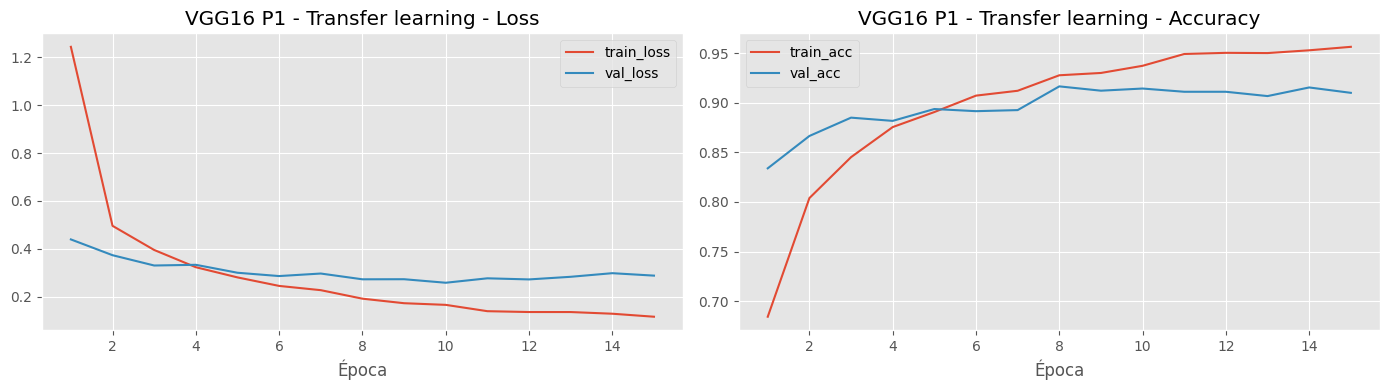

===== Diagnóstico: VGG16_P1_transfer =====
Mejor val_accuracy: 0.9164 (época 8)
train_accuracy en esa época: 0.9276  -> gap: 0.0112
Última época -> train_acc: 0.9562 | val_acc: 0.9099 | gap: 0.0463
val_loss mínima: 0.2590 (época 10); al final: 0.2887 (cambio +0.0297)
Veredicto: BUEN BALANCE: train y validación avanzan juntos, sin sobreajuste marcado.


In [ ]:
tf.keras.utils.set_random_seed(SEED)
model_vgg_p1, base_vgg_p1 = crear_modelo_preentrenado('VGG16', augmentation=False)
model_vgg_p1.summary()
H = entrenar(model_vgg_p1, 'VGG16_P1_transfer', 'Preentrenada', X_train_vgg, y_train, X_val_vgg, y_val, epochs=15)
graficar_historial(H, 'VGG16 P1 - Transfer learning')
diagnosticar('VGG16_P1_transfer')

En el `summary` se ve que de los ~14,8 M de parámetros solo 132 mil son entrenables (el top). Por eso cada época es relativamente rápida aunque la red sea grande.

Ya en la primera época llega a 0.834 en validación (la CNN desde cero arrancaba en 0.29-0.41), que es la ventaja de partir de los pesos de ImageNet. La mejor val_accuracy fue 0.9164 (época 8) con un gap de solo 1,1 puntos: con la base congelada casi no hay sobreajuste. Pero, como decíamos en la hipótesis, se queda por debajo de la mejor CNN desde cero (0.9544). Las características de ImageNet "tal cual" no alcanzan para resonancias.

Hacia el final el gap crece (4,6 puntos en la época 15), o sea que el top, aunque sea pequeño, también empieza a memorizar. Por eso probamos augmentation en P2.

### P2 - VGG16: Transfer learning + data augmentation

Mismo modelo, con el bloque de data augmentation antes de la base.

Hipótesis: menos sobreajuste del top. La val_accuracy puede no subir mucho, pero este modelo es mejor punto de partida para el fine-tuning, donde aumentan muchísimo los parámetros entrenables y, con ellos, el riesgo de sobreajuste.

[INFO] VGG16_P2_transfer_aug: 14,847,044 parámetros (132,356 entrenables)
Epoch 1/15
135/135 - 23s - 169ms/step - accuracy: 0.6777 - loss: 1.2708 - val_accuracy: 0.7644 - val_loss: 0.6610
Epoch 2/15
135/135 - 13s - 96ms/step - accuracy: 0.7755 - loss: 0.5781 - val_accuracy: 0.7742 - val_loss: 0.6103
Epoch 3/15
135/135 - 13s - 93ms/step - accuracy: 0.8135 - loss: 0.4814 - val_accuracy: 0.8219 - val_loss: 0.4862
Epoch 4/15
135/135 - 13s - 93ms/step - accuracy: 0.8281 - loss: 0.4386 - val_accuracy: 0.8284 - val_loss: 0.4552
Epoch 5/15
135/135 - 13s - 94ms/step - accuracy: 0.8475 - loss: 0.3968 - val_accuracy: 0.8382 - val_loss: 0.5001
Epoch 6/15
135/135 - 13s - 94ms/step - accuracy: 0.8633 - loss: 0.3646 - val_accuracy: 0.8350 - val_loss: 0.4730
Epoch 7/15
135/135 - 13s - 94ms/step - accuracy: 0.8731 - loss: 0.3292 - val_accuracy: 0.8556 - val_loss: 0.4030
Epoch 8/15
135/135 - 13s - 94ms/step - accuracy: 0.8717 - loss: 0.3434 - val_accuracy: 0.8458 - val_loss: 0.4245
Epoch 9/15
135/135 - 

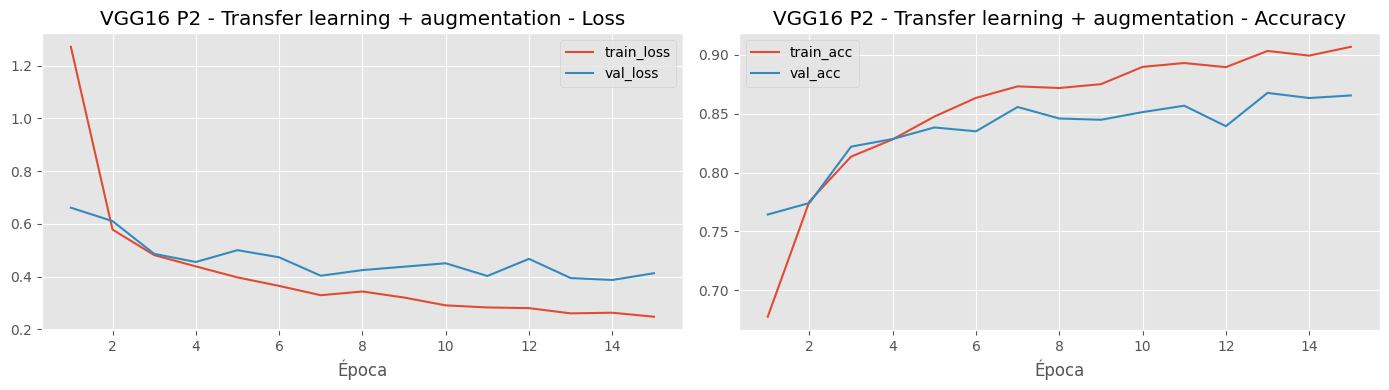

===== Diagnóstico: VGG16_P2_transfer_aug =====
Mejor val_accuracy: 0.8675 (época 13)
train_accuracy en esa época: 0.9031  -> gap: 0.0356
Última época -> train_acc: 0.9066 | val_acc: 0.8654 | gap: 0.0413
val_loss mínima: 0.3871 (época 14); al final: 0.4127 (cambio +0.0256)
Veredicto: BUEN BALANCE: train y validación avanzan juntos, sin sobreajuste marcado.


In [ ]:
tf.keras.utils.set_random_seed(SEED)
model_vgg, base_vgg = crear_modelo_preentrenado('VGG16', augmentation=True)
H = entrenar(model_vgg, 'VGG16_P2_transfer_aug', 'Preentrenada', X_train_vgg, y_train, X_val_vgg, y_val, epochs=15)
graficar_historial(H, 'VGG16 P2 - Transfer learning + augmentation')
diagnosticar('VGG16_P2_transfer_aug')

### P3 - VGG16: Fine-tuning del bloque 5

Descongelamos el último bloque convolucional (`block5_conv1` en adelante), igual que en el ejemplo de fine-tuning de clase, partiendo de los pesos de P2.

¿Por qué el último bloque? Los primeros bloques detectan cosas genéricas (bordes, texturas) que sirven también para resonancias, mientras que los últimos tienen características específicas de las clases de ImageNet, que son justamente las que hay que adaptar a tumores.

Detalles importantes (sesión 3):
- Hay que volver a compilar después de cambiar qué capas son entrenables (la función `entrenar` ya compila).
- Learning rate muy bajo (`1e-5`): la idea es ajustar un poco unos pesos que ya son buenos, no reentrenarlos. Con un lr alto se "destruye" lo aprendido (en clase vimos que con `lr=0.1` el fine-tuning se quedaba atascado).
- EarlyStopping con paciencia 4 sobre la val_loss.

In [ ]:
descongelar_desde(base_vgg, nombre_capa='block5_conv1')
H = entrenar(model_vgg, 'VGG16_P3_finetune_b5', 'Preentrenada', X_train_vgg, y_train, X_val_vgg, y_val,
             epochs=12, learning_rate=1e-5, callbacks=[callback_early_stopping(4)])
diagnosticar('VGG16_P3_finetune_b5')

Capas entrenables de la base: 4 de 19
[INFO] VGG16_P3_finetune_b5: 14,847,044 parámetros (7,211,780 entrenables)
Epoch 1/12
135/135 - 19s - 141ms/step - accuracy: 0.9164 - loss: 0.2319 - val_accuracy: 0.8838 - val_loss: 0.3206
Epoch 2/12
135/135 - 15s - 114ms/step - accuracy: 0.9350 - loss: 0.1764 - val_accuracy: 0.8849 - val_loss: 0.3590
Epoch 3/12
135/135 - 15s - 111ms/step - accuracy: 0.9457 - loss: 0.1471 - val_accuracy: 0.9121 - val_loss: 0.2864
Epoch 4/12
135/135 - 15s - 111ms/step - accuracy: 0.9518 - loss: 0.1280 - val_accuracy: 0.8969 - val_loss: 0.3143
Epoch 5/12
135/135 - 15s - 111ms/step - accuracy: 0.9574 - loss: 0.1161 - val_accuracy: 0.9055 - val_loss: 0.3212
Epoch 6/12
135/135 - 15s - 112ms/step - accuracy: 0.9611 - loss: 0.1029 - val_accuracy: 0.9316 - val_loss: 0.2345
Epoch 7/12
135/135 - 15s - 112ms/step - accuracy: 0.9667 - loss: 0.0901 - val_accuracy: 0.9110 - val_loss: 0.2965
Epoch 8/12
135/135 - 15s - 111ms/step - accuracy: 0.9681 - loss: 0.0847 - val_accuracy: 0

### P4 - VGG16: Fine-tuning progresivo (bloques 4 y 5)

Siguiendo la idea de descongelado progresivo, descongelamos también el bloque 4 y bajamos aún más el learning rate (`5e-6`), porque ahora se mueven muchos más pesos.

Hipótesis: como el dominio (resonancias) está lejos de ImageNet, adaptar más capas puede seguir ayudando. Pero con unas 4.300 imágenes de entrenamiento y millones de parámetros entrenables, también puede empezar a sobreajustar. La validación decide.

Capas entrenables de la base: 8 de 19
[INFO] VGG16_P4_finetune_b4b5: 14,847,044 parámetros (13,111,556 entrenables)
Epoch 1/12
135/135 - 25s - 186ms/step - accuracy: 0.9790 - loss: 0.0596 - val_accuracy: 0.9316 - val_loss: 0.2574
Epoch 2/12
135/135 - 20s - 146ms/step - accuracy: 0.9809 - loss: 0.0501 - val_accuracy: 0.9197 - val_loss: 0.3295
Epoch 3/12
135/135 - 19s - 144ms/step - accuracy: 0.9830 - loss: 0.0546 - val_accuracy: 0.9229 - val_loss: 0.3705
Epoch 4/12
135/135 - 20s - 145ms/step - accuracy: 0.9821 - loss: 0.0490 - val_accuracy: 0.9457 - val_loss: 0.2215
Epoch 5/12
135/135 - 20s - 147ms/step - accuracy: 0.9867 - loss: 0.0427 - val_accuracy: 0.9359 - val_loss: 0.2592
Epoch 6/12
135/135 - 20s - 145ms/step - accuracy: 0.9886 - loss: 0.0357 - val_accuracy: 0.9511 - val_loss: 0.2219
Epoch 7/12
135/135 - 20s - 145ms/step - accuracy: 0.9881 - loss: 0.0351 - val_accuracy: 0.9468 - val_loss: 0.2269
Epoch 8/12
135/135 - 19s - 144ms/step - accuracy: 0.9856 - loss: 0.0410 - val_accuracy

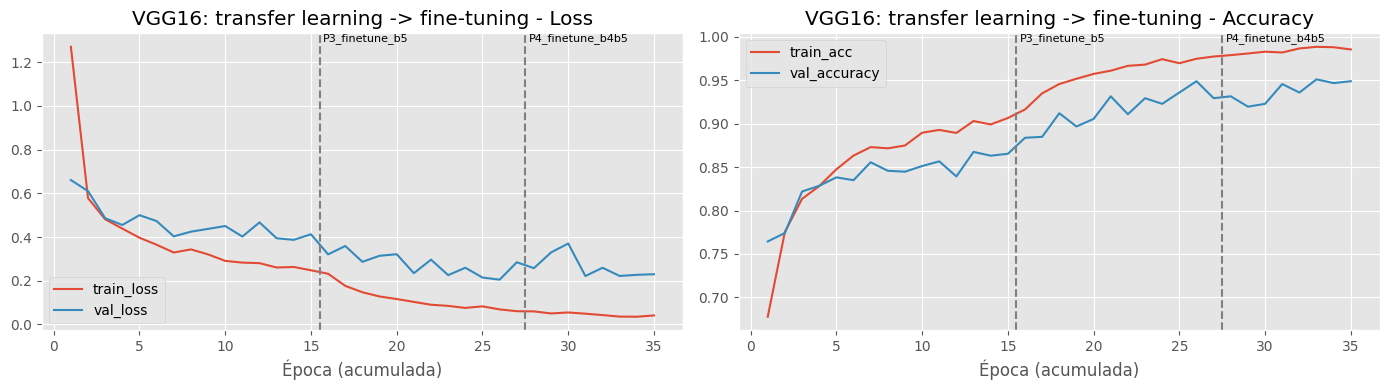

In [ ]:
descongelar_desde(base_vgg, nombre_capa='block4_conv1')
H = entrenar(model_vgg, 'VGG16_P4_finetune_b4b5', 'Preentrenada', X_train_vgg, y_train, X_val_vgg, y_val,
             epochs=12, learning_rate=5e-6, callbacks=[callback_early_stopping(4)])
diagnosticar('VGG16_P4_finetune_b4b5')
graficar_tl_ft(['VGG16_P2_transfer_aug', 'VGG16_P3_finetune_b5', 'VGG16_P4_finetune_b4b5'],
               'VGG16: transfer learning -> fine-tuning')

In [ ]:
exp_vgg = ['VGG16_P1_transfer', 'VGG16_P2_transfer_aug', 'VGG16_P3_finetune_b5', 'VGG16_P4_finetune_b4b5']
display(pd.DataFrame([r for r in resultados if r['experimento'] in exp_vgg])
        [['experimento', 'epocas', 'train_acc', 'val_acc', 'gap_acc', 'params_entrenables', 'tiempo_s']].round(4))

# model_vgg tiene los pesos después del fine-tuning (EarlyStopping restaura los mejores de la última etapa)
val_vgg_final = model_vgg.evaluate(X_val_vgg, y_val, verbose=0)[1]
print(f"VGG16 final (después de P4) -> val_acc: {val_vgg_final:.4f}")

# Comparamos con P1 (transfer sin augmentation), por si quedara mejor que todo lo demás
val_vgg_p1 = val_acc_de('VGG16_P1_transfer')
if val_vgg_p1 > val_vgg_final:
    print("Ojo: P1 (transfer sin augmentation) quedó mejor en validación que el modelo con fine-tuning.")
    modelo_vgg_elegido, nombre_vgg_elegido, val_vgg_elegido = model_vgg_p1, 'VGG16_P1_transfer', val_vgg_p1
else:
    modelo_vgg_elegido, nombre_vgg_elegido, val_vgg_elegido = model_vgg, 'VGG16_P4_finetune_b4b5', val_vgg_final
print("Modelo VGG16 elegido:", nombre_vgg_elegido)
modelo_vgg_elegido.save(os.path.join(BASE_FOLDER, 'mejor_vgg16.keras'))

,experimento,epocas,train_acc,val_acc,gap_acc,params_entrenables,tiempo_s
0,VGG16_P1_transfer,15,0.9276,0.9164,0.0112,132356,273.5826
1,VGG16_P2_transfer_aug,15,0.9031,0.8675,0.0356,132356,204.3837
2,VGG16_P3_finetune_b5,12,0.9748,0.9490,0.0259,7211780,188.4565
3,VGG16_P4_finetune_b4b5,8,0.9886,0.9511,0.0374,13111556,166.8876


VGG16 final (después de P4) -> val_acc: 0.9457
Modelo VGG16 elegido: VGG16_P4_finetune_b4b5


### Análisis VGG16

- P1 → P2: el augmentation bajó la val_accuracy de 0.9164 a 0.8675, y el train también bajó (de 0.93 a 0.90). Con la base congelada el top tiene pocos parámetros, y 15 épocas no le alcanzan para aprender con imágenes que cambian en cada época: es un subajuste leve. Viéndolo ahora, el augmentation aquí no resolvía un problema real, porque P1 casi no sobreajustaba.
- P2 → P3: el fine-tuning del bloque 5 sube la validación de 0.8675 a 0.9490, +8,2 puntos, el salto más grande de VGG16. Confirma la hipótesis: las últimas capas de ImageNet no están pensadas para resonancias, y adaptarlas es lo que hace la diferencia.
- P3 → P4: descongelar también el bloque 4 deja la mejor época en 0.9511, casi igual que P3, y el gap se mantiene estable (~3,7 puntos). Ya no suma mucho, pero tampoco sobreajustó. El EarlyStopping (que mira la val_loss) restauró la época 4, así que el modelo final queda en 0.9457.

El VGG16 final (P4) sí supera al de base congelada (P1), así que el fine-tuning valió la pena. Aun así queda un poco por debajo de la mejor CNN desde cero en validación (0.9457 contra 0.9544).

Antes de pasar a MobileNetV2 liberamos memoria. Nos quedamos con `X_test_vgg` para la evaluación final.

In [ ]:
del X_train_vgg, base_vgg_p1
gc.collect()

44951

## 6.3 MobileNetV2

Repetimos los mismos pasos. Como MobileNetV2 no tiene "bloques" tan marcados como VGG16 (son más de 150 capas pequeñas), para el fine-tuning descongelamos por número de capas, como en el ejemplo de clase: primero las últimas 30 y luego las últimas 60.

In [ ]:
X_train_mob, X_val_mob, X_test_mob = preparar_datos(mobilenet_v2.preprocess_input)
print("Rango después del preprocess de MobileNetV2:", X_train_mob.min(), X_train_mob.max())

Rango después del preprocess de MobileNetV2: -1.0 1.0


### P1 - MobileNetV2: Transfer learning (sin augmentation)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,586,948 (9.87 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

[INFO] MobileNetV2_P1_transfer: 2,586,948 parámetros (328,964 entrenables)
Epoch 1/15
135/135 - 61s - 451ms/step - accuracy: 0.7729 - loss: 0.6027 - val_accuracy: 0.8958 - val_loss: 0.2991
Epoch 2/15
135/135 - 3s - 22ms/step - accuracy: 0.8659 - loss: 0.3461 - val_accuracy: 0.9023 - val_loss: 0.2826
Epoch 3/15
135/135 - 3s - 24ms/step - accuracy: 0.8896 - loss: 0.2863 - val_accuracy: 0.9045 - val_loss: 0.2660
Epoch 4/15
135/135 - 3s - 22ms/step - accuracy: 0.9050 - loss: 0.2464 - val_accuracy: 0.8990 - val_loss: 0.2628
Epoch 5/15
135/135 - 3s - 21ms/step - accuracy: 0.9218 - loss: 0.2057 - val_accuracy: 0.9142 - val_loss: 0.2313
Epoch 6/15
135/135 - 3s - 21ms/step - accuracy: 0.9264 - loss: 0.1913 - val_accuracy: 0.9110 - val_loss: 0.2269
Epoch 7/15
135/135 - 3s - 23ms/step - accuracy: 0.9355 - loss: 0.1665 - val_accuracy: 0.9110 - val_loss: 0.2347
Epoch 8/15
135/135 - 3s - 23ms/step - accuracy: 0.9411 - loss: 0.1560 - val_accuracy: 0.9131 - val_loss: 0.2233
Epoch 9/15
135/135 - 3s - 2

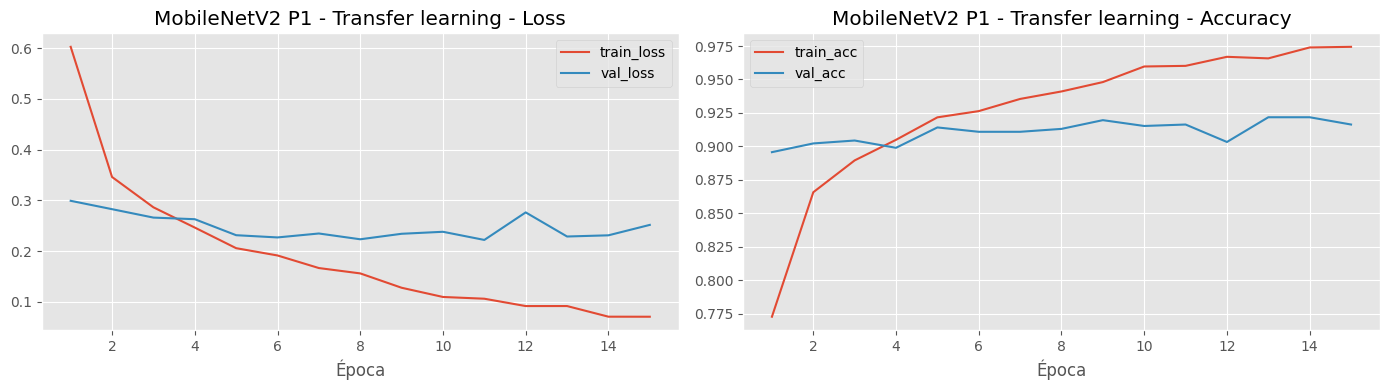

===== Diagnóstico: MobileNetV2_P1_transfer =====
Mejor val_accuracy: 0.9218 (época 13)
train_accuracy en esa época: 0.9658  -> gap: 0.0439
Última época -> train_acc: 0.9744 | val_acc: 0.9164 | gap: 0.0580
val_loss mínima: 0.2220 (época 11); al final: 0.2516 (cambio +0.0296)
Veredicto: SOBREAJUSTE: el train sigue mejorando pero la validación se estanca o empeora (la val_loss sube desde su mínimo y/o el gap es grande).


In [ ]:
tf.keras.utils.set_random_seed(SEED)
model_mob_p1, base_mob_p1 = crear_modelo_preentrenado('MobileNetV2', augmentation=False)
model_mob_p1.summary()
H = entrenar(model_mob_p1, 'MobileNetV2_P1_transfer', 'Preentrenada', X_train_mob, y_train, X_val_mob, y_val, epochs=15)
graficar_historial(H, 'MobileNetV2 P1 - Transfer learning')
diagnosticar('MobileNetV2_P1_transfer')

### P2 - MobileNetV2: Transfer learning + data augmentation

[INFO] MobileNetV2_P2_transfer_aug: 2,586,948 parámetros (328,964 entrenables)
Epoch 1/15
135/135 - 17s - 124ms/step - accuracy: 0.7401 - loss: 0.6718 - val_accuracy: 0.7524 - val_loss: 0.6327
Epoch 2/15
135/135 - 5s - 40ms/step - accuracy: 0.8177 - loss: 0.4585 - val_accuracy: 0.7828 - val_loss: 0.5786
Epoch 3/15
135/135 - 6s - 42ms/step - accuracy: 0.8463 - loss: 0.4066 - val_accuracy: 0.7763 - val_loss: 0.6005
Epoch 4/15
135/135 - 6s - 43ms/step - accuracy: 0.8617 - loss: 0.3596 - val_accuracy: 0.8219 - val_loss: 0.4798
Epoch 5/15
135/135 - 6s - 41ms/step - accuracy: 0.8656 - loss: 0.3515 - val_accuracy: 0.8208 - val_loss: 0.4574
Epoch 6/15
135/135 - 6s - 45ms/step - accuracy: 0.8770 - loss: 0.3152 - val_accuracy: 0.8208 - val_loss: 0.5592
Epoch 7/15
135/135 - 6s - 41ms/step - accuracy: 0.8777 - loss: 0.3325 - val_accuracy: 0.8469 - val_loss: 0.3873
Epoch 8/15
135/135 - 6s - 45ms/step - accuracy: 0.8833 - loss: 0.2893 - val_accuracy: 0.8252 - val_loss: 0.4847
Epoch 9/15
135/135 - 6s

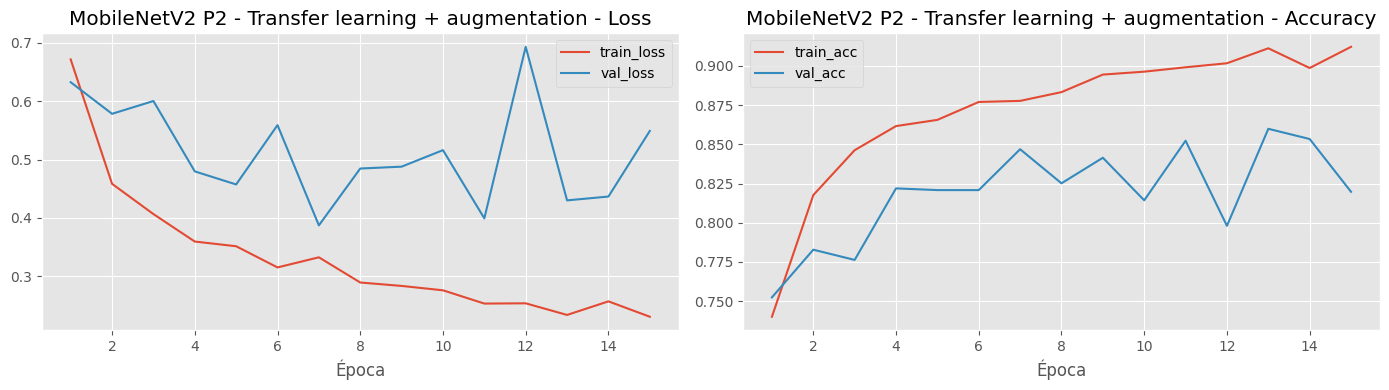

===== Diagnóstico: MobileNetV2_P2_transfer_aug =====
Mejor val_accuracy: 0.8599 (época 13)
train_accuracy en esa época: 0.9113  -> gap: 0.0513
Última época -> train_acc: 0.9122 | val_acc: 0.8198 | gap: 0.0924
val_loss mínima: 0.3873 (época 7); al final: 0.5492 (cambio +0.1619)
Veredicto: SOBREAJUSTE: el train sigue mejorando pero la validación se estanca o empeora (la val_loss sube desde su mínimo y/o el gap es grande).


In [ ]:
tf.keras.utils.set_random_seed(SEED)
model_mob, base_mob = crear_modelo_preentrenado('MobileNetV2', augmentation=True)
H = entrenar(model_mob, 'MobileNetV2_P2_transfer_aug', 'Preentrenada', X_train_mob, y_train, X_val_mob, y_val, epochs=15)
graficar_historial(H, 'MobileNetV2 P2 - Transfer learning + augmentation')
diagnosticar('MobileNetV2_P2_transfer_aug')

### P3 - MobileNetV2: Fine-tuning de las últimas 30 capas

In [ ]:
descongelar_desde(base_mob, ultimas_n=30)
H = entrenar(model_mob, 'MobileNetV2_P3_finetune_30', 'Preentrenada', X_train_mob, y_train, X_val_mob, y_val,
             epochs=12, learning_rate=1e-5, callbacks=[callback_early_stopping(4)])
diagnosticar('MobileNetV2_P3_finetune_30')

Capas entrenables de la base: 19 de 154
[INFO] MobileNetV2_P3_finetune_30: 2,586,948 parámetros (1,839,684 entrenables)
Epoch 1/12
135/135 - 15s - 110ms/step - accuracy: 0.9238 - loss: 0.2144 - val_accuracy: 0.8436 - val_loss: 0.4562
Epoch 2/12
135/135 - 6s - 47ms/step - accuracy: 0.9252 - loss: 0.2015 - val_accuracy: 0.8415 - val_loss: 0.4663
Epoch 3/12
135/135 - 7s - 49ms/step - accuracy: 0.9376 - loss: 0.1775 - val_accuracy: 0.8523 - val_loss: 0.4346
Epoch 4/12
135/135 - 6s - 47ms/step - accuracy: 0.9371 - loss: 0.1666 - val_accuracy: 0.8480 - val_loss: 0.4661
Epoch 5/12
135/135 - 7s - 50ms/step - accuracy: 0.9446 - loss: 0.1456 - val_accuracy: 0.8708 - val_loss: 0.3886
Epoch 6/12
135/135 - 6s - 47ms/step - accuracy: 0.9485 - loss: 0.1406 - val_accuracy: 0.8762 - val_loss: 0.3693
Epoch 7/12
135/135 - 7s - 50ms/step - accuracy: 0.9457 - loss: 0.1360 - val_accuracy: 0.8719 - val_loss: 0.4045
Epoch 8/12
135/135 - 6s - 46ms/step - accuracy: 0.9474 - loss: 0.1426 - val_accuracy: 0.8806 -

### P4 - MobileNetV2: Fine-tuning progresivo (últimas 60 capas)

Capas entrenables de la base: 39 de 154
[INFO] MobileNetV2_P4_finetune_60: 2,586,948 parámetros (2,260,740 entrenables)
Epoch 1/12
135/135 - 17s - 126ms/step - accuracy: 0.9611 - loss: 0.1066 - val_accuracy: 0.8675 - val_loss: 0.4248
Epoch 2/12
135/135 - 7s - 54ms/step - accuracy: 0.9599 - loss: 0.1080 - val_accuracy: 0.8740 - val_loss: 0.4147
Epoch 3/12
135/135 - 8s - 56ms/step - accuracy: 0.9637 - loss: 0.0986 - val_accuracy: 0.8990 - val_loss: 0.3266
Epoch 4/12
135/135 - 7s - 54ms/step - accuracy: 0.9634 - loss: 0.0982 - val_accuracy: 0.8827 - val_loss: 0.3730
Epoch 5/12
135/135 - 8s - 58ms/step - accuracy: 0.9623 - loss: 0.1018 - val_accuracy: 0.8990 - val_loss: 0.2910
Epoch 6/12
135/135 - 8s - 56ms/step - accuracy: 0.9667 - loss: 0.0892 - val_accuracy: 0.8849 - val_loss: 0.3270
Epoch 7/12
135/135 - 7s - 53ms/step - accuracy: 0.9748 - loss: 0.0806 - val_accuracy: 0.8914 - val_loss: 0.3430
Epoch 8/12
135/135 - 8s - 56ms/step - accuracy: 0.9700 - loss: 0.0796 - val_accuracy: 0.9262 -

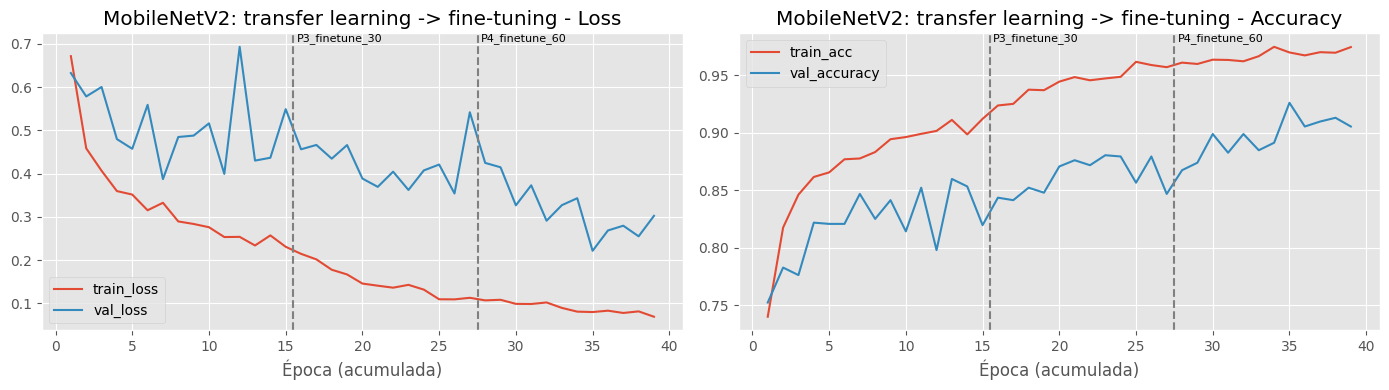

In [ ]:
descongelar_desde(base_mob, ultimas_n=60)
H = entrenar(model_mob, 'MobileNetV2_P4_finetune_60', 'Preentrenada', X_train_mob, y_train, X_val_mob, y_val,
             epochs=12, learning_rate=5e-6, callbacks=[callback_early_stopping(4)])
diagnosticar('MobileNetV2_P4_finetune_60')
graficar_tl_ft(['MobileNetV2_P2_transfer_aug', 'MobileNetV2_P3_finetune_30', 'MobileNetV2_P4_finetune_60'],
               'MobileNetV2: transfer learning -> fine-tuning')

In [ ]:
exp_mob = ['MobileNetV2_P1_transfer', 'MobileNetV2_P2_transfer_aug', 'MobileNetV2_P3_finetune_30', 'MobileNetV2_P4_finetune_60']
display(pd.DataFrame([r for r in resultados if r['experimento'] in exp_mob])
        [['experimento', 'epocas', 'train_acc', 'val_acc', 'gap_acc', 'params_entrenables', 'tiempo_s']].round(4))

val_mob_final = model_mob.evaluate(X_val_mob, y_val, verbose=0)[1]
print(f"MobileNetV2 final (después de P4) -> val_acc: {val_mob_final:.4f}")

val_mob_p1 = val_acc_de('MobileNetV2_P1_transfer')
if val_mob_p1 > val_mob_final:
    print("Ojo: P1 (transfer sin augmentation) quedó mejor en validación que el modelo con fine-tuning.")
    modelo_mob_elegido, nombre_mob_elegido, val_mob_elegido = model_mob_p1, 'MobileNetV2_P1_transfer', val_mob_p1
else:
    modelo_mob_elegido, nombre_mob_elegido, val_mob_elegido = model_mob, 'MobileNetV2_P4_finetune_60', val_mob_final
print("Modelo MobileNetV2 elegido:", nombre_mob_elegido)
modelo_mob_elegido.save(os.path.join(BASE_FOLDER, 'mejor_mobilenetv2.keras'))

del X_train_mob
gc.collect()

,experimento,epocas,train_acc,val_acc,gap_acc,params_entrenables,tiempo_s
0,MobileNetV2_P1_transfer,15,0.9658,0.9218,0.0439,328964,106.0049
1,MobileNetV2_P2_transfer_aug,15,0.9113,0.8599,0.0513,328964,104.6015
2,MobileNetV2_P3_finetune_30,12,0.9474,0.8806,0.0668,1839684,92.8091
3,MobileNetV2_P4_finetune_60,12,0.9700,0.9262,0.0438,2260740,101.5468


MobileNetV2 final (después de P4) -> val_acc: 0.9262
Modelo MobileNetV2 elegido: MobileNetV2_P4_finetune_60


11367

## 6.4 Comparación VGG16 vs MobileNetV2 (en validación)

Comparamos las dos arquitecturas con la validación para escoger la mejor preentrenada. Además de la accuracy miramos el número de parámetros y el tiempo de entrenamiento, que en una aplicación real (por ejemplo, un sistema de apoyo en un hospital con pocos recursos) pesan bastante.

,arquitectura,modelo_elegido,val_acc,params_total,tiempo_total_min
0,VGG16,VGG16_P4_finetune_b4b5,0.9457,14847044,13.8885
1,MobileNetV2,MobileNetV2_P4_finetune_60,0.9262,2586948,6.7494


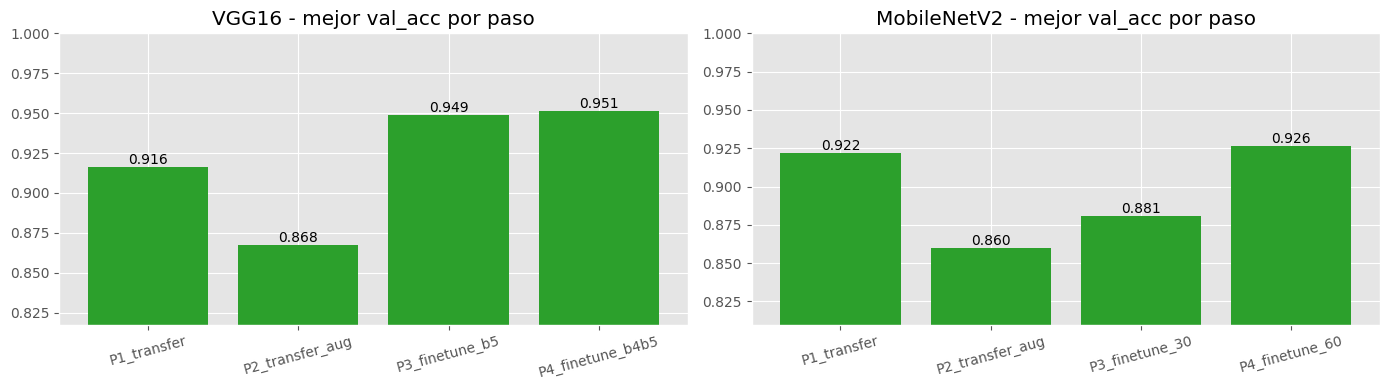

Mejor arquitectura preentrenada según validación: VGG16


In [ ]:
def tiempo_min(nombres):
    return sum(r['tiempo_s'] for r in resultados if r['experimento'] in nombres) / 60


comparacion_pre = pd.DataFrame({
    'arquitectura': ['VGG16', 'MobileNetV2'],
    'modelo_elegido': [nombre_vgg_elegido, nombre_mob_elegido],
    'val_acc': [val_vgg_elegido, val_mob_elegido],
    'params_total': [modelo_vgg_elegido.count_params(), modelo_mob_elegido.count_params()],
    'tiempo_total_min': [tiempo_min(exp_vgg), tiempo_min(exp_mob)],
})
display(comparacion_pre.round(4))

plt.style.use("ggplot")
plt.figure(figsize=(14, 4))
for i, (exps, titulo) in enumerate([(exp_vgg, 'VGG16'), (exp_mob, 'MobileNetV2')]):
    plt.subplot(1, 2, i + 1)
    vals = [val_acc_de(n) for n in exps]
    plt.bar([n.split('_', 1)[1] for n in exps], vals, color='tab:green')
    for j, v in enumerate(vals):
        plt.text(j, v, f"{v:.3f}", ha='center', va='bottom')
    plt.ylim(max(0, min(vals) - 0.05), 1.0)
    plt.title(f"{titulo} - mejor val_acc por paso")
    plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

MEJOR_PRE = 'VGG16' if val_vgg_elegido >= val_mob_elegido else 'MobileNetV2'
print("Mejor arquitectura preentrenada según validación:", MEJOR_PRE)

### Análisis de las arquitecturas preentrenadas

Mejor val_accuracy de cada paso:

| Paso | VGG16 | MobileNetV2 |
|---|---|---|
| P1 - Base congelada | 0.9164 | 0.9218 |
| P2 - + Data augmentation | 0.8675 | 0.8599 |
| P3 - Fine-tuning 1 (bloque 5 / últimas 30 capas) | 0.9490 | 0.8806 |
| P4 - Fine-tuning 2 (bloques 4-5 / últimas 60 capas) | 0.9511 | 0.9262 |
| Modelo final (pesos restaurados por EarlyStopping) | 0.9457 | 0.9262 |

- Con base congelada las dos quedan parecidas (0.916 y 0.922), y en las dos el augmentation con la base congelada bajó la validación unos 5-6 puntos.
- El fine-tuning le sirvió mucho más a VGG16: con el bloque 5 ya recupera +8,2 puntos. MobileNetV2 subió más lento: +2,1 puntos con las últimas 30 capas y +4,6 más con las últimas 60. Tiene sentido: en MobileNetV2 las "últimas 30 capas" son pocas convoluciones pequeñas (al dejar las BatchNorm congeladas solo quedaron 19 capas entrenables), así que hubo que descongelar más para adaptarla.
- MobileNetV2 sobreajusta más: su gap está entre 4 y 7 puntos, contra 2,6-3,7 de VGG16. Su top recibe 1.280 características (VGG16 da 512), así que tiene más del doble de parámetros entrenables desde P1.
- VGG16 gana en validación (0.9457 contra 0.9262), pero tiene 5,7 veces más parámetros (14,8 M contra 2,6 M) y tardó el doble (13,9 contra 6,7 minutos en total).

Ninguna de las dos preentrenadas superó en validación a la mejor CNN desde cero (0.9544). Habrá que ver si eso se mantiene en test.

# 7. Evaluación final sobre test y comparación de estrategias

Ahora sí usamos por primera vez el conjunto de test, con los tres modelos finalistas:

1. El mejor modelo desde cero (escogido con validación en la sección 5).
2. El modelo final de VGG16.
3. El modelo final de MobileNetV2.

Ninguno de los tres se escogió mirando el test, así que la comparación es justa.

Además de la accuracy calculamos dos métricas que en este problema importan mucho:

- F1 macro: el promedio del F1 de las 4 clases. Penaliza si el modelo descuida alguna clase.
- Tumores no detectados: cuántas imágenes con tumor el modelo clasificó como "sin tumor". Es el error más grave desde el punto de vista médico (un paciente enfermo que se va a casa), así que queremos verlo aparte.

===================== Desde cero (E6_aug_lr_bajo) =====================
Test loss: 0.1772 | Test accuracy: 0.9435
              precision    recall  f1-score   support

      glioma     0.9506    0.9363    0.9434       267
  meningioma     0.9160    0.9124    0.9142       251
   sin tumor     0.9296    0.9429    0.9362       140
   hipófisis     0.9699    0.9810    0.9754       263

    accuracy                         0.9435       921
   macro avg     0.9415    0.9431    0.9423       921
weighted avg     0.9435    0.9435    0.9435       921

Tumores clasificados como 'sin tumor': 10 de 781 (1.28 %)


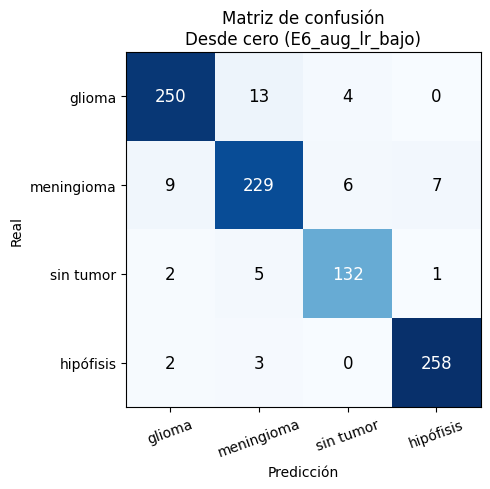

===================== VGG16 (VGG16_P4_finetune_b4b5) =====================
Test loss: 0.2871 | Test accuracy: 0.9403
              precision    recall  f1-score   support

      glioma     0.9761    0.9176    0.9459       267
  meningioma     0.9000    0.9323    0.9159       251
   sin tumor     0.9343    0.9143    0.9242       140
   hipófisis     0.9487    0.9848    0.9664       263

    accuracy                         0.9403       921
   macro avg     0.9398    0.9372    0.9381       921
weighted avg     0.9412    0.9403    0.9403       921

Tumores clasificados como 'sin tumor': 9 de 781 (1.15 %)


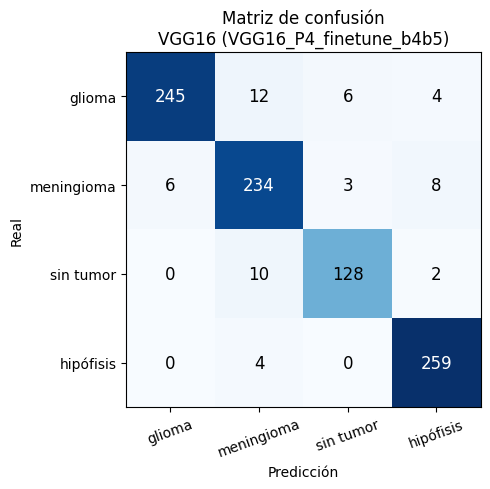

===================== MobileNetV2 (MobileNetV2_P4_finetune_60) =====================
Test loss: 0.3751 | Test accuracy: 0.9012
              precision    recall  f1-score   support

      glioma     0.9426    0.8614    0.9002       267
  meningioma     0.8482    0.8685    0.8583       251
   sin tumor     0.9453    0.8643    0.9030       140
   hipófisis     0.8938    0.9924    0.9405       263

    accuracy                         0.9012       921
   macro avg     0.9075    0.8967    0.9005       921
weighted avg     0.9034    0.9012    0.9007       921

Tumores clasificados como 'sin tumor': 7 de 781 (0.90 %)


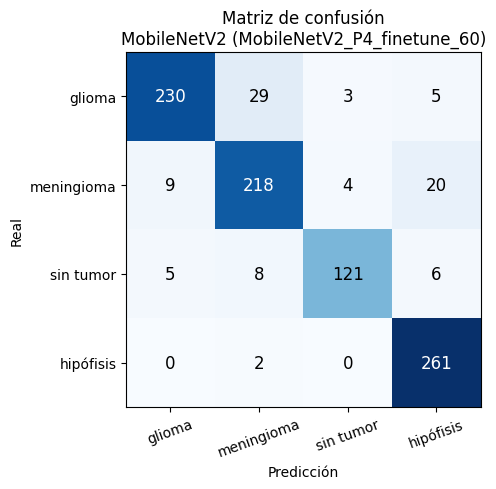

In [ ]:
def evaluar_en_test(model, X_t, y_t, nombre):
    '''Evaluación final: loss/accuracy, classification report, matriz de confusión y errores graves.'''
    loss, acc = model.evaluate(X_t, y_t, verbose=0)
    prob = model.predict(X_t, batch_size=BATCH_SIZE, verbose=0)
    pred = prob.argmax(axis=1)

    print(f"===================== {nombre} =====================")
    print(f"Test loss: {loss:.4f} | Test accuracy: {acc:.4f}")
    print(classification_report(y_t, pred, labels=list(range(NUM_CLASES)), target_names=CLASES,
                                digits=4, zero_division=0))
    reporte = classification_report(y_t, pred, labels=list(range(NUM_CLASES)), target_names=CLASES,
                                    output_dict=True, zero_division=0)

    con_tumor = y_t != IDX_SIN_TUMOR
    no_detectados = int(np.sum(con_tumor & (pred == IDX_SIN_TUMOR)))
    print(f"Tumores clasificados como 'sin tumor': {no_detectados} de {int(con_tumor.sum())} "
          f"({no_detectados / con_tumor.sum() * 100:.2f} %)")

    cm = confusion_matrix(y_t, pred, labels=list(range(NUM_CLASES)))
    plt.style.use('default')
    plt.figure(figsize=(5.5, 5))
    plt.imshow(cm, cmap='Blues')
    for i in range(NUM_CLASES):
        for j in range(NUM_CLASES):
            plt.text(j, i, cm[i, j], ha='center', va='center',
                     color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=12)
    plt.xticks(range(NUM_CLASES), CLASES, rotation=20)
    plt.yticks(range(NUM_CLASES), CLASES)
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.title(f"Matriz de confusión\n{nombre}")
    plt.tight_layout()
    plt.show()

    return {'modelo': nombre, 'test_loss': loss, 'test_acc': acc,
            'f1_macro': reporte['macro avg']['f1-score'],
            'recall_sin_tumor': reporte['sin tumor']['recall'],
            'tumores_no_detectados': no_detectados}, pred


res_test = []
r, pred_scratch = evaluar_en_test(mejor_modelo_scratch, X_test, y_test, f"Desde cero ({MEJOR_SCRATCH})")
res_test.append(r)
r, pred_vgg = evaluar_en_test(modelo_vgg_elegido, X_test_vgg, y_test, f"VGG16 ({nombre_vgg_elegido})")
res_test.append(r)
r, pred_mob = evaluar_en_test(modelo_mob_elegido, X_test_mob, y_test, f"MobileNetV2 ({nombre_mob_elegido})")
res_test.append(r)

## 7.1 Tabla comparativa final

,modelo,estrategia,val_acc,test_acc,diferencia_val_test,f1_macro,tumores_no_detectados,test_loss,params_total,tiempo_entreno_min
0,Desde cero (E6_aug_lr_bajo),Desde cero,0.9544,0.9435,0.0109,0.9423,10,0.1772,3864100,11.9191
1,VGG16 (VGG16_P4_finetune_b4b5),Preentrenada,0.9457,0.9403,0.0054,0.9381,9,0.2871,14847044,9.3288
2,MobileNetV2 (MobileNetV2_P4_finetune_60),Preentrenada,0.9262,0.9012,0.0250,0.9005,7,0.3751,2586948,4.9826


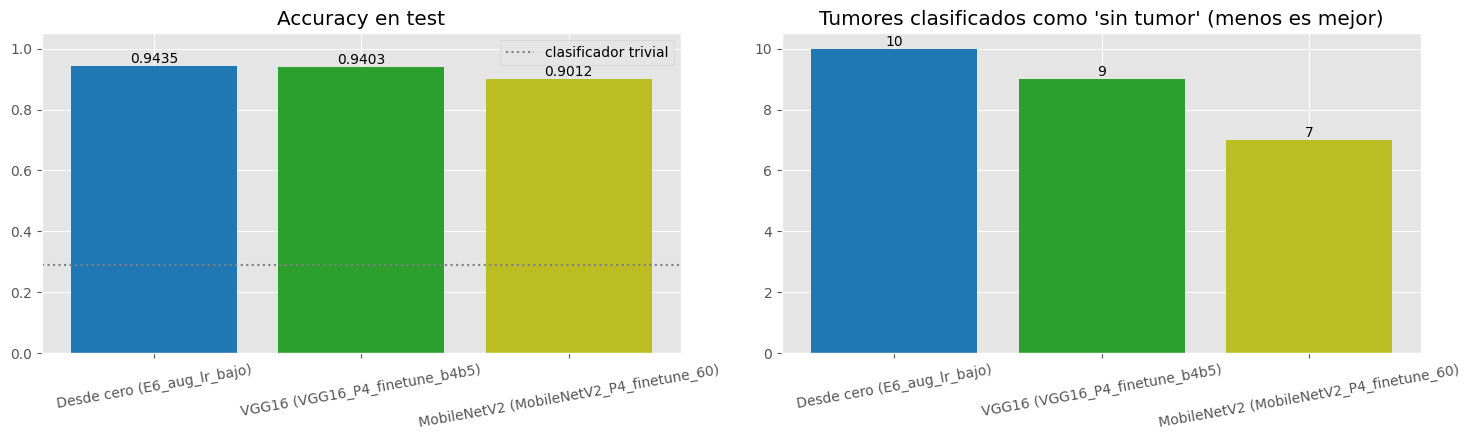

In [ ]:
df_test = pd.DataFrame(res_test)
df_test['estrategia'] = ['Desde cero', 'Preentrenada', 'Preentrenada']
df_test['val_acc'] = [val_acc_de(MEJOR_SCRATCH), val_vgg_elegido, val_mob_elegido]
df_test['diferencia_val_test'] = df_test['val_acc'] - df_test['test_acc']
df_test['params_total'] = [mejor_modelo_scratch.count_params(), modelo_vgg_elegido.count_params(),
                           modelo_mob_elegido.count_params()]
# Tiempo que costó llegar a cada modelo final (si el elegido es P1, solo P1; si no, P2 + P3 + P4)
df_test['tiempo_entreno_min'] = [
    tiempo_min([MEJOR_SCRATCH]),
    tiempo_min([exp_vgg[0]] if nombre_vgg_elegido == exp_vgg[0] else exp_vgg[1:]),
    tiempo_min([exp_mob[0]] if nombre_mob_elegido == exp_mob[0] else exp_mob[1:]),
]
display(df_test[['modelo', 'estrategia', 'val_acc', 'test_acc', 'diferencia_val_test', 'f1_macro',
                 'tumores_no_detectados', 'test_loss', 'params_total', 'tiempo_entreno_min']].round(4))

plt.style.use("ggplot")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
colores = ['tab:blue', 'tab:green', 'tab:olive']
axes[0].bar(df_test['modelo'], df_test['test_acc'], color=colores)
for i, v in enumerate(df_test['test_acc']):
    axes[0].text(i, v, f"{v:.4f}", ha='center', va='bottom')
axes[0].axhline(acc_trivial_test, color='gray', linestyle=':', label='clasificador trivial')
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Accuracy en test")
axes[0].legend()
axes[1].bar(df_test['modelo'], df_test['tumores_no_detectados'], color=colores)
for i, v in enumerate(df_test['tumores_no_detectados']):
    axes[1].text(i, v, str(v), ha='center', va='bottom')
axes[1].set_title("Tumores clasificados como 'sin tumor' (menos es mejor)")
for ax in axes:
    ax.tick_params(axis='x', rotation=10)
plt.tight_layout()
plt.show()

## 7.2 Evolución del entrenamiento: desde cero vs preentrenadas

Ponemos en la misma gráfica la val_accuracy de los modelos finales a lo largo de todas sus épocas (en las preentrenadas sumamos transfer learning + fine-tuning). Así se ve la velocidad de convergencia de cada estrategia.

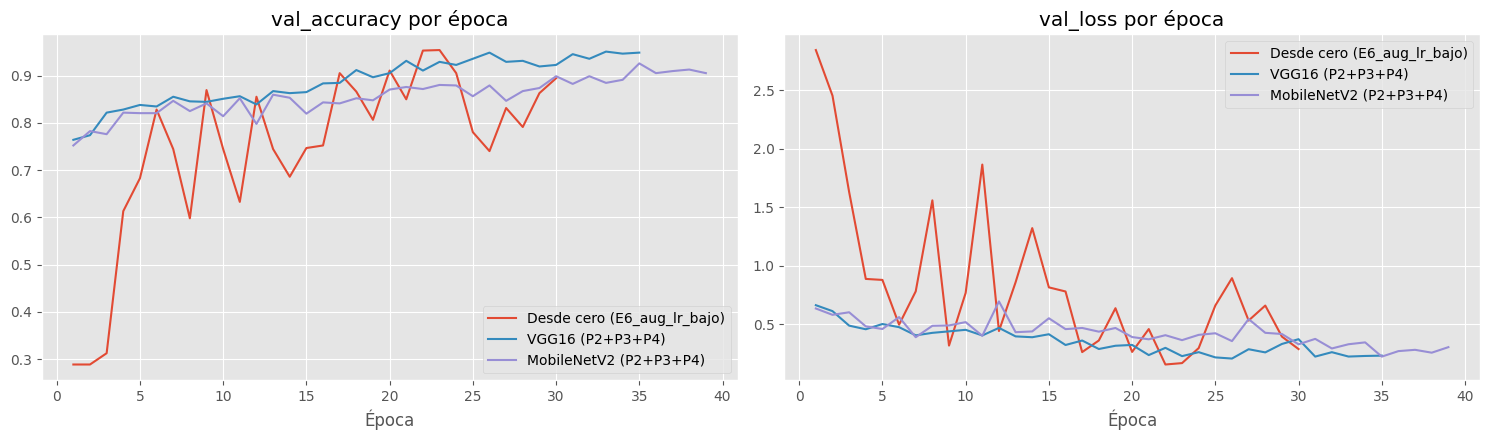

In [ ]:
def curva_acumulada(nombres, metrica):
    v = []
    for n in nombres:
        v += list(historiales[n][metrica])
    return v


curvas = {
    f"Desde cero ({MEJOR_SCRATCH})": [MEJOR_SCRATCH],
    'VGG16 (P2+P3+P4)': exp_vgg[1:],
    'MobileNetV2 (P2+P3+P4)': exp_mob[1:],
}
plt.style.use("ggplot")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for etiqueta, nombres in curvas.items():
    for ax, metrica in zip(axes, ['val_accuracy', 'val_loss']):
        valores = curva_acumulada(nombres, metrica)
        ax.plot(np.arange(1, len(valores) + 1), valores, label=etiqueta)
axes[0].set_title("val_accuracy por época")
axes[1].set_title("val_loss por época")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend()
plt.tight_layout()
plt.show()

## 7.3 ¿En qué se equivocan los modelos?

Miramos algunas imágenes de test que el mejor modelo desde cero clasifica mal, y qué dice la mejor preentrenada sobre esas mismas imágenes. Así vemos si los errores son "razonables" (imágenes difíciles o clases parecidas) o si fallan en casos fáciles.

Errores desde cero: 52 | Errores VGG16: 55
Errores en común: 24

Confusiones más frecuentes (real -> predicho), modelo desde cero:
glioma -> meningioma       13
meningioma -> glioma        9
meningioma -> hipófisis     7
meningioma -> sin tumor     6
sin tumor -> meningioma     5
glioma -> sin tumor         4
Name: count, dtype: int64


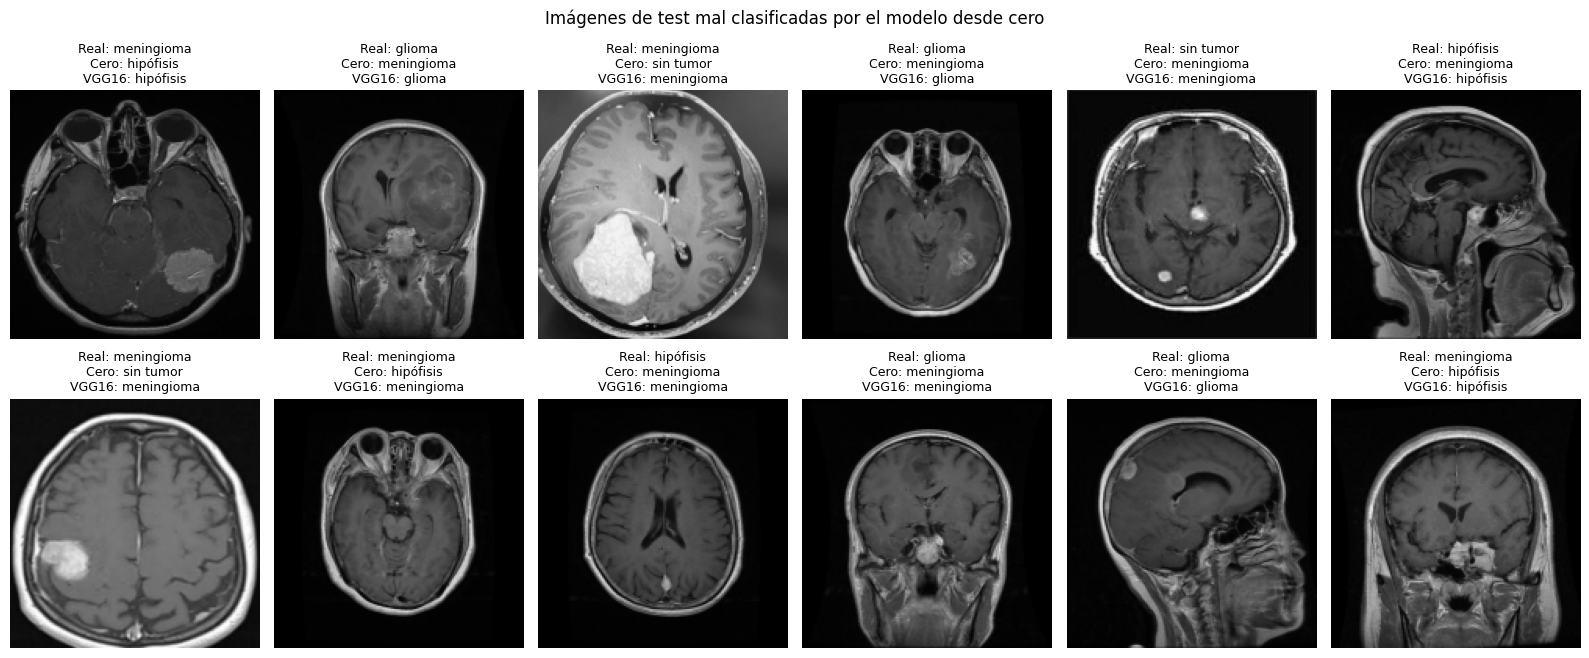

In [ ]:
pred_pre = pred_vgg if MEJOR_PRE == 'VGG16' else pred_mob
errores = np.where(pred_scratch != y_test)[0]
print(f"Errores desde cero: {len(errores)} | Errores {MEJOR_PRE}: {np.sum(pred_pre != y_test)}")
print(f"Errores en común: {np.sum((pred_scratch != y_test) & (pred_pre != y_test))}")

# ¿Qué confusiones son las más frecuentes en el modelo desde cero?
confusiones = pd.Series([f"{CLASES[y_test[i]]} -> {CLASES[pred_scratch[i]]}" for i in errores]).value_counts()
print("\nConfusiones más frecuentes (real -> predicho), modelo desde cero:")
print(confusiones.head(6))

plt.style.use('default')
plt.figure(figsize=(16, 7))
for n, idx in enumerate(errores[:12]):
    plt.subplot(2, 6, n + 1)
    plt.imshow(X_test[idx])
    plt.title(f"Real: {CLASES[y_test[idx]]}\n"
              f"Cero: {CLASES[pred_scratch[idx]]}\n"
              f"{MEJOR_PRE}: {CLASES[pred_pre[idx]]}", fontsize=9)
    plt.axis('off')
plt.suptitle("Imágenes de test mal clasificadas por el modelo desde cero")
plt.tight_layout()
plt.show()

- Errores desde cero: 52. Errores VGG16: 55. En común: solo 24. Más de la mitad de las imágenes que falla un modelo, el otro la acierta. Eso sugiere que combinar los dos (un *ensemble*) podría mejorar los resultados; lo dejamos como mejora posible.
- La confusión más común es entre glioma y meningioma (13 en un sentido y 9 en el otro), como esperábamos: los dos son masas dentro del cráneo y en algunas vistas se parecen bastante.
- Lo que no nos gustó: hay meningiomas grandes y muy visibles (por ejemplo la 3ª y la 7ª imagen, masas blancas enormes) que la CNN desde cero clasificó como "sin tumor", mientras que VGG16 los acertó. La 3ª además tiene un contraste y un fondo distintos al resto (fondo gris en vez de negro). Eso nos hace pensar que la red desde cero es más sensible a cambios de apariencia de la imagen que las preentrenadas, que vieron millones de fotos variadas en ImageNet.

## 7.4 ¿Dónde mira la CNN desde cero? (Grad-CAM)

Para cerrar usamos Grad-CAM (sesión 3) sobre el mejor modelo desde cero. En un problema médico esto es clave: queremos comprobar que la red mira la zona del tumor y no algo que no tiene que ver (el borde del cráneo, el fondo negro, una marca del equipo), porque eso sería un "atajo" que no funcionaría con imágenes de otro hospital.

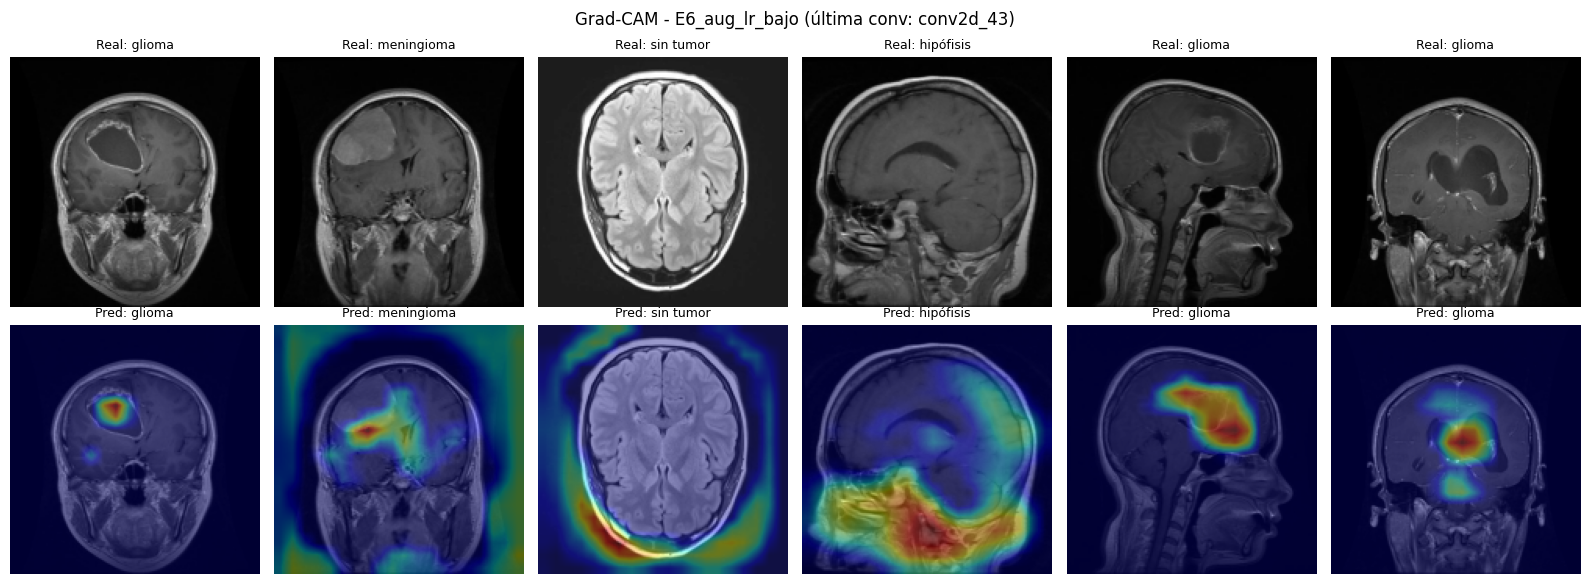

In [ ]:
ultima_conv = [c for c in mejor_modelo_scratch.layers if isinstance(c, Conv2D)][-1]
grad_model = tf.keras.Model(inputs=mejor_modelo_scratch.inputs,
                            outputs=[ultima_conv.output, mejor_modelo_scratch.output])


def gradcam(imagen):
    entrada = tf.cast(imagen[np.newaxis], tf.float32)
    with tf.GradientTape() as tape:
        conv_out, pred = grad_model(entrada, training=False)
        clase_predicha = int(tf.argmax(pred[0]))
        score = pred[:, clase_predicha]
    grads = tape.gradient(score, conv_out)
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(conv_out[0] * pesos, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    heatmap = tf.image.resize(heatmap[..., np.newaxis], (IMG_SIZE, IMG_SIZE))
    return tf.squeeze(heatmap).numpy(), clase_predicha


# Un ejemplo de cada clase de tumor + dos sin tumor
rng = np.random.default_rng(SEED)
ejemplos = [rng.choice(np.where(y_test == c)[0]) for c in range(NUM_CLASES)]
ejemplos += list(rng.choice(np.where(y_test != IDX_SIN_TUMOR)[0], 2, replace=False))

plt.figure(figsize=(16, 6))
for n, idx in enumerate(ejemplos):
    hm, c = gradcam(X_test[idx])
    plt.subplot(2, 6, n + 1)
    plt.imshow(X_test[idx])
    plt.title(f"Real: {CLASES[y_test[idx]]}", fontsize=9)
    plt.axis('off')
    plt.subplot(2, 6, n + 7)
    plt.imshow(X_test[idx])
    plt.imshow(hm, cmap='jet', alpha=0.4)
    plt.title(f"Pred: {CLASES[c]}", fontsize=9)
    plt.axis('off')
plt.suptitle(f"Grad-CAM - {MEJOR_SCRATCH} (última conv: {ultima_conv.name})")
plt.tight_layout()
plt.show()

Lo que vemos en las 6 imágenes:

- Gliomas (1ª, 5ª y 6ª): el mapa cae sobre el tumor, justo encima de la masa o en el borde de la lesión. Aquí la red mira lo que tiene que mirar.
- Meningioma (2ª): la zona más caliente está cerca de la masa, pero el mapa también se reparte por zonas sin interés, como los bordes de la imagen.
- Sin tumor (3ª): el calor se concentra en el borde del cráneo, abajo, y no en el cerebro. Para esta clase no hay una región concreta que buscar, pero que mire el borde del cráneo es una señal de alerta.
- Hipófisis (4ª): el mapa se va hacia el cerebelo y la base del cráneo, no hacia la zona donde está la hipófisis. Nuestra sospecha es que la red aprendió que muchas imágenes de esta clase son cortes sagitales (vistos de lado) y usa la forma del corte como pista.

En resumen, para los gliomas la red mira la zona correcta, pero para "sin tumor" e hipófisis hay indicios de atajos. Con 6 imágenes no lo podemos afirmar, pero si este modelo fuera a usarse de verdad habría que revisarlo con muchos más ejemplos y con imágenes de otro hospital.

# 8. Conclusiones

In [ ]:
# Resumen automático con los números de esta ejecución (para que las conclusiones salgan de los datos)
scratch = df_test.iloc[0]
pre = df_test.iloc[1:]
mejor_pre_row = pre.loc[pre['test_acc'].idxmax()]
ganador = df_test.loc[df_test['test_acc'].idxmax()]

print(f"Clasificador trivial en test: {acc_trivial_test:.4f}")
for _, fila in df_test.iterrows():
    print(f"{fila['modelo']:<45}: acc {fila['test_acc']:.4f} | F1 macro {fila['f1_macro']:.4f} | "
          f"tumores no detectados {fila['tumores_no_detectados']} | {fila['params_total']:,} parámetros")
print()
print(f"Mejor modelo en test: {ganador['modelo']} ({ganador['estrategia']}) con {ganador['test_acc']:.4f}")
print(f"Diferencia mejor preentrenada vs desde cero: {(mejor_pre_row['test_acc'] - scratch['test_acc']) * 100:+.2f} puntos porcentuales")

# Cuánto aportó el fine-tuning frente al transfer learning puro (en validación)
for arq, exps in [('VGG16', exp_vgg), ('MobileNetV2', exp_mob)]:
    tl = max(val_acc_de(exps[0]), val_acc_de(exps[1]))
    ft = max(val_acc_de(exps[2]), val_acc_de(exps[3]))
    print(f"{arq}: mejor val_acc con base congelada {tl:.4f} -> con fine-tuning {ft:.4f} ({(ft - tl) * 100:+.2f} pp)")

Clasificador trivial en test: 0.2899
Desde cero (E6_aug_lr_bajo)                  : acc 0.9435 | F1 macro 0.9423 | tumores no detectados 10 | 3,864,100 parámetros
VGG16 (VGG16_P4_finetune_b4b5)               : acc 0.9403 | F1 macro 0.9381 | tumores no detectados 9 | 14,847,044 parámetros
MobileNetV2 (MobileNetV2_P4_finetune_60)     : acc 0.9012 | F1 macro 0.9005 | tumores no detectados 7 | 2,586,948 parámetros

Mejor modelo en test: Desde cero (E6_aug_lr_bajo) (Desde cero) con 0.9435
Diferencia mejor preentrenada vs desde cero: -0.33 puntos porcentuales
VGG16: mejor val_acc con base congelada 0.9164 -> con fine-tuning 0.9511 (+3.47 pp)
MobileNetV2: mejor val_acc con base congelada 0.9218 -> con fine-tuning 0.9262 (+0.43 pp)


## 8.1 Comparación entre estrategias

| Modelo | val_acc | test_acc | F1 macro | Tumores no detectados | Parámetros | Tiempo de entrenamiento |
|---|---|---|---|---|---|---|
| Desde cero (E6) | 0.9544 | 0.9435 | 0.9423 | 10 de 781 (1,28 %) | 3,9 M | 11,9 min |
| VGG16 + fine-tuning (P4) | 0.9457 | 0.9403 | 0.9381 | 9 de 781 (1,15 %) | 14,8 M | 9,3 min |
| MobileNetV2 + fine-tuning (P4) | 0.9262 | 0.9012 | 0.9005 | 7 de 781 (0,90 %) | 2,6 M | 5,0 min |

Rendimiento y generalización. Los tres modelos superan con mucha diferencia al clasificador trivial (0.29), así que todos aprendieron patrones reales. La CNN desde cero queda primera, pero solo 0,33 puntos por encima de VGG16, que son 3 imágenes de 921. Como vimos que entre dos corridas iguales los resultados cambian 2-3 puntos, esto lo consideramos un empate técnico. MobileNetV2 sí queda claramente atrás: 4 puntos menos, y además es la que más cae de validación a test (2,5 puntos, con la test loss más alta: 0.375). Eso cuadra con que en validación ya era la que más sobreajustaba. En los otros dos la caída de validación a test es pequeña (1,1 y 0,5 puntos), o sea que las decisiones tomadas con validación generalizaron bien. Ayuda que hayamos quitado los duplicados: si no, el test habría tenido 412 imágenes repetidas del train y los resultados habrían salido inflados.

Evolución del entrenamiento. En la gráfica 7.2 se ve la diferencia de velocidad: las preentrenadas con la base congelada ya sacan 0.83-0.90 en validación en la primera época, porque traen detectores de bordes y texturas, mientras que la CNN desde cero arranca en el nivel del azar (0.29) y necesitó 23 épocas y augmentation para llegar a su mejor resultado. En tiempo total no hubo tanta diferencia (11,9 minutos desde cero contra 9,3 de VGG16 sumando P2, P3 y P4).

Transfer learning vs fine-tuning. Con la base congelada las dos preentrenadas se quedaron en ~0.92 en validación, por debajo de la CNN desde cero. Lo que las hizo competitivas fue el fine-tuning, sobre todo en VGG16 (+3,5 puntos respecto a la mejor base congelada y +8,2 respecto a P2). En MobileNetV2 la mejora final fue de apenas +0,4 puntos sobre su base congelada. Como ImageNet no tiene resonancias, las características "tal cual" se quedan cortas, y adaptar las últimas capas es necesario.

Sobreajuste y subajuste.
- Desde cero: el problema principal fue el sobreajuste. E1 y E2 llegaron al 100 % en train con 8 puntos de gap y la val_loss subiendo desde la época 5-6. BatchNorm + Dropout fue lo que más ayudó (+4 puntos), y el augmentation cerró el gap casi por completo (de 4,0 a 1,3 puntos). La L2 no aportó.
- Preentrenadas: con la base congelada el sobreajuste es bajo (gap de 1,1 puntos en VGG16 P1). El único caso de subajuste del proyecto fue P2 (base congelada + augmentation): train y validación bajaron a la vez porque el top no alcanzó a aprender en 15 épocas. En el fine-tuning los parámetros entrenables se multiplican (hasta 13,1 M en VGG16 P4) y hubo que controlarlo con learning rate muy bajo (1e-5 y 5e-6) y EarlyStopping. VGG16 se mantuvo estable (gap ~3,7 puntos), y MobileNetV2 sobreajustó más (4-7 puntos).

Errores graves. MobileNetV2, con la peor accuracy, es la que menos tumores deja pasar como "sin tumor" (7), pero en parte es porque predice "sin tumor" con menos frecuencia (su recall en esa clase es el más bajo, 0.864). Entre la CNN desde cero (10) y VGG16 (9) la diferencia es mínima. En cualquier caso, ninguno sería aceptable para uso clínico real tal como está: 7-10 pacientes con tumor de cada 781 se irían a casa con un "sin tumor".

## 8.2 Ventajas e inconvenientes

| | CNN desde cero | Redes preentrenadas |
|---|---|---|
| Ventajas | Control total de la arquitectura. Modelo pequeño (3,9 M de parámetros, casi 4 veces menos que VGG16). Aprende directamente del dominio de las resonancias. En este problema logró la mejor accuracy. | Muy buen punto de partida: 0.83-0.90 en la primera época. Convergen en menos épocas. El fine-tuning adapta el conocimiento general al dominio médico. Parecen más robustas a cambios de apariencia (acertaron meningiomas grandes que la CNN desde cero confundió). |
| Inconvenientes | Hicieron falta 6 experimentos para llegar al modelo final. Sobreajusta con facilidad con solo ~4.300 imágenes. Validación muy inestable entre épocas. El Grad-CAM muestra posibles atajos en algunas clases. | VGG16 es pesada (14,8 M). Hay que respetar el preprocesamiento de cada red (y tener cuidado con cómo interactúa con el augmentation, ver 8.4). La base congelada sola se queda corta en este dominio, y el fine-tuning es delicado (learning rate, qué capas descongelar). |

## 8.3 ¿Qué estrategia es mejor para este problema y por qué?

Con los números de esta ejecución, la CNN desde cero (E6) es la ganadora, por poco: 0.9435 en test contra 0.9403 de VGG16 con fine-tuning. Es un resultado interesante, porque lo habitual es que las preentrenadas ganen. Creemos que pasa por tres cosas:

1. El dominio está muy lejos de ImageNet. Con la base congelada las características de ImageNet solo llegaron a ~0.92, así que el conocimiento previo ayuda menos que en problemas con fotos normales.
2. El problema es relativamente acotado: 4 clases con formas bastante características, en imágenes casi siempre en gris y con fondo negro. Para eso, unas 4.300 imágenes alcanzan para entrenar una red pequeña si está bien regularizada (sin BatchNorm, Dropout y augmentation la CNN desde cero se quedaba en ~0.91).
3. El tamaño de la red importa con pocos datos: con 3,9 M de parámetros tiene menos capacidad para memorizar que una VGG16 con 13 M de parámetros entrenables.

Aun así, siendo honestos, la diferencia con VGG16 es de 3 imágenes y está dentro de la variación entre corridas. Lo que sí podemos afirmar es que las dos estrategias llegan a ~94 %, y que para que las preentrenadas sean competitivas el fine-tuning es obligatorio. Si tuviéramos que llevar uno a producción nos quedaríamos con la CNN desde cero por ser casi 4 veces más liviana. Antes de usarla habría que revisar los atajos que se vieron en el Grad-CAM, y la ventaja de VGG16 en robustez podría hacernos cambiar de opinión con datos de otro hospital.

Entre las dos preentrenadas, VGG16 fue claramente mejor que MobileNetV2 (4 puntos más en test). Al principio pensábamos que, si la diferencia era pequeña, MobileNetV2 sería la mejor opción por ser más liviana, pero 4 puntos es demasiado para compensarlo.

## 8.4 Lo que nos llevamos del proyecto

- Revisar los datos antes de entrenar es tan importante como el modelo. Encontrar los duplicados entre Training y Testing (412 imágenes de test repetidas) cambió cómo dividimos los datos, y además mostró que la clase "sin tumor" tenía la mitad de imágenes de lo que parecía.
- Cuando un resultado no tiene sentido, primero hay que sospechar del código. En la primera ejecución, todas las preentrenadas con augmentation se quedaban en ~25 % de validación (como adivinar al azar) mientras el train subía al 80-95 %. Esa combinación no se explica con sobreajuste normal. El problema era que la capa `RandomContrast` de Keras 3 recorta los valores al rango 0-255, y las imágenes de las preentrenadas ya venían con el `preprocess_input` aplicado (MobileNetV2 en [-1, 1], VGG16 con valores negativos). En entrenamiento todos los valores negativos quedaban en 0, pero en validación no, así que la red aprendía con imágenes distintas a las que veía después. Lo corregimos pasándole a `RandomContrast` el rango correcto de cada red.
- La validación manda en todas las decisiones; el test se toca una sola vez al final. Y con una validación tan nerviosa, hay que fijarse en la tendencia y no en diferencias de 1 punto.
- Cada técnica de regularización resuelve un problema concreto. Hay que mirar las curvas, identificar el problema (aquí, sobreajuste por pocos datos) y escoger la técnica que lo ataque. No todas ayudan: la L2 no aportó, y el augmentation con base congelada empeoró.
- En problemas médicos la accuracy no lo es todo: importa qué tipo de error comete el modelo.

Posibles mejoras: recortar los bordes negros de las resonancias para que la red vea el cerebro con más resolución, probar imágenes más grandes (224×224), usar pesos por clase en la pérdida para penalizar más los tumores no detectados, combinar la CNN desde cero con VGG16 (solo comparten 24 de sus ~50 errores), repetir cada experimento con varias semillas para promediar la variación entre corridas, y probar otras arquitecturas como ResNet50.

# 9. Generación del PDF

Esto es lo del ejemplo del enunciado para pasar el notebook a PDF. Hay que guardar antes el notebook en la carpeta `BASE_FOLDER` de Drive.

> Nota: en la versión actual de Colab el paquete `texlive-generic-recommended` ya no existe y hace fallar el `apt install`; ahora se llama `texlive-plain-generic`.

In [4]:
%%capture
if EN_COLAB:
    name_IPYNB_file = '07MIAR_Proyecto_Programacion_Solucion.ipynb'
    get_ipython().system(
        "apt update >> /dev/null && apt install texlive-xetex texlive-fonts-recommended texlive-plain-generic >> /dev/null"
    )
    get_ipython().system(
        "jupyter nbconvert --output-dir='$BASE_FOLDER' '$BASE_FOLDER''$name_IPYNB_file' --to pdf"
    )

#  Declaración de uso de inteligencia artificial

 Para este proyecto usamos el asistente de IA Claude (Anthropic), en su herramienta Claude Code, como apoyo en el desarrollo. Lo declaramos de acuerdo con la normativa de la maestría.

 En qué nos ayudó la IA:
 - Redactar el código del notebook: carga del dataset, detección de duplicados y evaluacion de data.
 - Diagnosticar problemas técnicos durante el desarrollo: el error de RandomContrast con el preprocess_input de las redes preentrenadas y la generación del PDF en Colab.

 Entendemos el contenido del trabajo y podemos explicar y defender las decisiones que se tomaron en él.

In [6]:
!jupyter nbconvert --to pdf "/content/drive/MyDrive/07MIAR_Proyecto_Programacion/07MIAR_Proyecto_Programacion_Solucion.ipynb" --output-dir "/content/drive/MyDrive/07MIAR_Proyecto_Programacion/" 2>&1 | tail -30

[NbConvertApp] Converting notebook /content/drive/MyDrive/07MIAR_Proyecto_Programacion/07MIAR_Proyecto_Programacion_Solucion.ipynb to pdf
[NbConvertApp] Support files will be in 07MIAR_Proyecto_Programacion_Solucion_files/
[NbConvertApp] Making directory ./07MIAR_Proyecto_Programacion_Solucion_files
[NbConvertApp] Writing 367667 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 3793307 bytes to /content/drive/MyDrive/07MIAR_Proyecto_Programacion/07MIAR_Proyecto_Programacion_Solucion.pdf
